### Define project paths

In [28]:
            
from pathlib import Path

# Main project directory
PROJECT_DIR = Path(r"G:\AI Project ExcelR")

# Dataset directories
IMAGE_DIR = PROJECT_DIR / "data" / "images"
PARQUET_DIR = IMAGE_DIR / "parquet"
NUTRITION_DIR = PROJECT_DIR / "data" / "nutrition"

# Notebook and output directories
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
OUTPUT_DIR = PROJECT_DIR / "outputs"
EDA_DIR = OUTPUT_DIR / "eda"
NOTES_DIR = PROJECT_DIR / "notes"

# Dataset files
TRAIN_PATH = (
    PARQUET_DIR / "data"
    / "train-00000-of-00001-dbae6752a5d31c49.parquet"
)

TEST_PATH = (
    PARQUET_DIR / "data"
    / "test-00000-of-00001-899c7c7e401d279b.parquet"
)

METADATA_PATH = IMAGE_DIR / "dataset_infos.json"
INDB_PATH = NUTRITION_DIR / "INDB.xlsx"

print("Project directory:", PROJECT_DIR)
print("Training dataset exists:", TRAIN_PATH.exists())
print("Test dataset exists:", TEST_PATH.exists())
print("Dataset metadata exists:", METADATA_PATH.exists())
print("INDB workbook exists:", INDB_PATH.exists())


Project directory: G:\AI Project ExcelR
Training dataset exists: True
Test dataset exists: True
Dataset metadata exists: True
INDB workbook exists: True


In [29]:

# Create the project folders if they do not already exist

folders = [
    IMAGE_DIR,
    PARQUET_DIR,
    NUTRITION_DIR,
    NOTEBOOK_DIR,
    OUTPUT_DIR,
    EDA_DIR,
    NOTES_DIR,
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)
    print("Ready:", folder)

print("\nProject folder setup completed.")


Ready: G:\AI Project ExcelR\data\images
Ready: G:\AI Project ExcelR\data\images\parquet
Ready: G:\AI Project ExcelR\data\nutrition
Ready: G:\AI Project ExcelR\notebooks
Ready: G:\AI Project ExcelR\outputs
Ready: G:\AI Project ExcelR\outputs\eda
Ready: G:\AI Project ExcelR\notes

Project folder setup completed.


### Check Python environment and libraries

libraries installed => in virtual environment here:
G:\AI Project ExcelR\AI_proj_env\

In [30]:

import sys
import platform
import importlib.metadata

# 1. Check Python environment
print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Operating system:", platform.platform())

# 2. Check important project libraries
required_packages = [
    "tensorflow",
    "datasets",
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "pillow",
    "openpyxl",
    "scikit-learn",
    "ImageHash",
    "pyarrow",
]

print("\nLibrary availability:")

for package in required_packages:
    try:
        version = importlib.metadata.version(package)
        print(f"{package}: Installed (version {version})")
    except importlib.metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")


Python version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Python executable: g:\AI Project ExcelR\AI_proj_env\Scripts\python.exe
Operating system: Windows-10-10.0.26200-SP0

Library availability:
tensorflow: Installed (version 2.21.0)
datasets: Installed (version 5.1.0)
pandas: Installed (version 3.0.6)
numpy: Installed (version 2.4.6)
matplotlib: Installed (version 3.11.2)
seaborn: Installed (version 0.13.2)
pillow: Installed (version 12.3.0)
openpyxl: Installed (version 3.1.5)
scikit-learn: Installed (version 1.9.1)
ImageHash: Installed (version 4.3.2)
pyarrow: Installed (version 26.0.0)


### library import

In [31]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
import imagehash

from datasets import load_dataset
import pyarrow.parquet as pq

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow import keras

import openpyxl

print("All project libraries imported successfully.")
print("TensorFlow version:", tf.__version__)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All project libraries imported successfully.
TensorFlow version: 2.21.0
Pandas version: 3.0.6
NumPy version: 2.4.6


### Inspect the image dataset

In [32]:

# Inspect the structure of the training and test datasets

dataset_files = {
    "Train": TRAIN_PATH,
    "Test": TEST_PATH,
}

for split_name, file_path in dataset_files.items():
    print(f"\n{'=' * 50}")
    print(f"{split_name.upper()} DATASET")
    print("=" * 50)

    parquet_file = pq.ParquetFile(file_path)

    print("File size (GB):", round(file_path.stat().st_size / (1024**3), 3))
    print("Number of rows:", parquet_file.metadata.num_rows)
    print("Number of row groups:", parquet_file.metadata.num_row_groups)
    print("\nSchema:")
    print(parquet_file.schema)



TRAIN DATASET
File size (GB): 1.267
Number of rows: 5328
Number of row groups: 1

Schema:
required group field_id=-1 schema {
  optional group field_id=-1 image {
    optional binary field_id=-1 bytes;
    optional binary field_id=-1 path (String);
  }
  optional int64 field_id=-1 label;
}


TEST DATASET
File size (GB): 0.224
Number of rows: 941
Number of row groups: 1

Schema:
required group field_id=-1 schema {
  optional group field_id=-1 image {
    optional binary field_id=-1 bytes;
    optional binary field_id=-1 path (String);
  }
  optional int64 field_id=-1 label;
}




### Observation — Image Dataset Structure

- The training dataset contains 5,328 image records, while the test dataset contains 941 image records, giving a total of 6,269 records across both splits.
- The training Parquet file occupies approximately 1.267 GB, and the test Parquet file occupies approximately 0.224 GB on disk.
- Both files contain one Parquet row group and share the same schema, consisting of an image field and a numeric label field.
- The image field contains the image bytes and an associated path, while the label field stores the class ID as an integer.
- Both Parquet files were accessible and their metadata could be read successfully.

### Conclusion

The dataset structure is consistent across the training and test splits, and the required image and label fields are available for subsequent analysis and model development.

### Limitation

This inspection validates the Parquet structure and record counts only. It does not confirm that every embedded image can be decoded, that image labels are correct, or that duplicate images and train-test leakage are absent. These checks will be performed in subsequent data-quality steps.


### Load and inspect label mapping

In [33]:

# Load the official class names from the dataset metadata

import json

with open(METADATA_PATH, "r", encoding="utf-8") as file:
    metadata = json.load(file)

class_names = (
    metadata["rajistics--indian_food_images"]
    ["features"]["label"]["names"]
)

print("Number of classes:", len(class_names))
print("\nLabel ID mapping:")

for label_id, class_name in enumerate(class_names):
    print(f"{label_id}: {class_name}")


Number of classes: 20

Label ID mapping:
0: burger
1: butter_naan
2: chai
3: chapati
4: chole_bhature
5: dal_makhani
6: dhokla
7: fried_rice
8: idli
9: jalebi
10: kaathi_rolls
11: kadai_paneer
12: kulfi
13: masala_dosa
14: momos
15: paani_puri
16: pakode
17: pav_bhaji
18: pizza
19: samosa


### Observation — Food Class Mapping

- The dataset metadata identifies 20 food classes, with label IDs ranging from 0 to 19.
- Each numeric label ID is associated with a corresponding food category, providing the class mapping required for image classification.
- The mapping was loaded successfully from the local dataset metadata file.

**Conclusion:** The class mapping is available for subsequent dataset analysis and model development.

**Limitation:** This confirms the metadata mapping only; it does not verify whether individual images are correctly labelled.

Inspect the dataset records

In [34]:
# Cell 8: Inspect sample records from the training and test datasets

for split_name, file_path in {
    "Train": TRAIN_PATH,
    "Test": TEST_PATH
}.items():

    print(f"\n{'=' * 50}")
    print(f"{split_name.upper()} DATASET — SAMPLE RECORDS")
    print("=" * 50)

    sample_df = pd.read_parquet(file_path).head(5)

    print("\nColumns:")
    print(sample_df.columns.tolist())

    print("\nData types:")
    print(sample_df.dtypes)

    print("\nFirst 5 records:")
    display(sample_df)


TRAIN DATASET — SAMPLE RECORDS

Columns:
['image', 'label']

Data types:
image    object
label     int64
dtype: object

First 5 records:


,image,label
0,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,6
1,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,3
2,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,11
3,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,16
4,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1



TEST DATASET — SAMPLE RECORDS

Columns:
['image', 'label']

Data types:
image    object
label     int64
dtype: object

First 5 records:


,image,label
0,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,16
1,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,16
2,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,5
3,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,4
4,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1


### Observation — Sample Record Inspection

- Both training and test datasets contain the expected `image` and `label` columns.
- Image data is stored as binary bytes within dictionary-like objects, while labels are stored as 64-bit integers.
- The first five records from each split were read successfully, confirming that sample records are accessible for further inspection.

**Conclusion:** The observed record structure is suitable for proceeding with image-data quality checks and class-distribution analysis.

**Limitation:** Only five records per split were inspected. Full image decoding, dimension validation, and label verification remain pending.

### Verify label values and class counts

Before plotting the class distribution, let's calculate the record counts for every class in both splits. This will help identify missing classes and quantify class imbalance

### Visualize class distribution

Training — minimum class count: 112
Training — maximum class count: 358
Training — max/min class-count ratio: 3.20:1
Test — minimum class count: 18
Test — maximum class count: 67
Test — max/min class-count ratio: 3.72:1


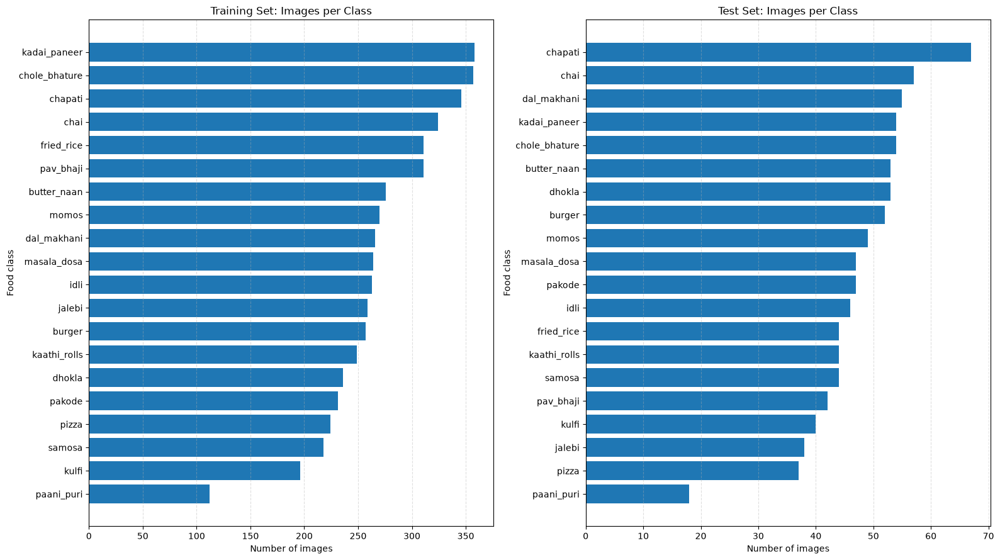

In [35]:
# Cell 10: Visualize class distribution in training and test datasets

fig, axes = plt.subplots(1, 2, figsize=(16, 9))

for ax, (split_name, file_path) in zip(
    axes,
    [("Training", TRAIN_PATH), ("Test", TEST_PATH)]
):
    labels = pd.read_parquet(file_path, columns=["label"])["label"]

    counts = (
        labels.value_counts()
        .reindex(range(len(class_names)), fill_value=0)
    )

    plot_df = pd.DataFrame({
        "Food class": class_names,
        "Image count": counts.values
    }).sort_values("Image count", ascending=True)

    ax.barh(plot_df["Food class"], plot_df["Image count"])
    ax.set_title(f"{split_name} Set: Images per Class")
    ax.set_xlabel("Number of images")
    ax.set_ylabel("Food class")
    ax.grid(axis="x", linestyle="--", alpha=0.4)

    print(f"{split_name} — minimum class count: {counts.min()}")
    print(f"{split_name} — maximum class count: {counts.max()}")
    print(
        f"{split_name} — max/min class-count ratio: "
        f"{counts.max() / counts.min():.2f}:1"
    )

plt.tight_layout()
plt.show()

### Observation — Visual Class Distribution Analysis

- The training class counts range from 112 to 358 images, producing a maximum-to-minimum ratio of 3.20:1.
- The test class counts range from 18 to 67 images, producing a ratio of 3.72:1.
- The distribution plots provide a visual comparison of the representation of each food class in both splits.
- `paani_puri` is the least represented class in both datasets and may require particular attention during per-class model evaluation.

**Conclusion:** Class representation is unequal in both splits. We will retain the original distribution for data-quality analysis and evaluate model performance by class before deciding whether imbalance-handling measures are necessary.

**Limitation:** Class counts alone do not establish whether imbalance will materially reduce model performance. That must be assessed using validation results and per-class metrics.

### C13 — Validate embedded image bytes in batches

We'll now validate all 6,269 image records without loading both large Parquet files into memory at once. This cell checks whether image bytes are present, whether each image can be decoded, and its dimensions when decoding succeeds.

We'll record the results for C14 and save the detailed CSV report in C15. No images will be deleted or modified.

However, C13 does not check for:
- Incorrect food labels.
- Images containing multiple dishes or irrelevant content.
- Exact or near-duplicate images.
- Whether the training and test sets contain duplicate images.
- Whether the image resolution is sufficient for reliable classification.

In [36]:
# C13: Validate embedded image bytes in batches

from io import BytesIO
from PIL import Image, UnidentifiedImageError
import pandas as pd
import pyarrow.parquet as pq

BATCH_SIZE = 128

integrity_records = []

dataset_files = {
    "train": TRAIN_PATH,
    "test": TEST_PATH
}

for split_name, file_path in dataset_files.items():

    print(f"\n{'=' * 60}")
    print(f"VALIDATING {split_name.upper()} IMAGES")
    print("=" * 60)

    parquet_file = pq.ParquetFile(file_path)
    total_records = parquet_file.metadata.num_rows
    processed_records = 0

    for batch in parquet_file.iter_batches(
        batch_size=BATCH_SIZE,
        columns=["image", "label"]
    ):
        batch_df = batch.to_pandas()

        for record_index, row in batch_df.iterrows():

            label_value = row["label"]
            image_data = row["image"]

            record = {
                "split": split_name,
                "record_index": processed_records,
                "label_id": label_value,
                "food_class": None,
                "image_path": None,
                "status": None,
                "width": None,
                "height": None,
                "aspect_ratio": None,
                "format": None,
                "error_details": None
            }

            # Validate the label before using it for class mapping
            try:
                label_id = int(label_value)

                if not 0 <= label_id < len(class_names):
                    raise ValueError(f"Label ID outside expected range: {label_id}")

                record["label_id"] = label_id
                record["food_class"] = class_names[label_id]

            except Exception as exc:
                record["status"] = "invalid_label"
                record["error_details"] = (
                    f"{type(exc).__name__}: {exc}"
                )
                integrity_records.append(record)
                processed_records += 1
                continue

            # Extract embedded image bytes and optional path
            if not isinstance(image_data, dict):
                record["status"] = "invalid_image_structure"
                record["error_details"] = (
                    f"Expected image dictionary, got {type(image_data).__name__}"
                )
                integrity_records.append(record)
                processed_records += 1
                continue

            image_bytes = image_data.get("bytes")
            record["image_path"] = image_data.get("path")

            if not isinstance(image_bytes, (bytes, bytearray)) or len(image_bytes) == 0:
                record["status"] = "missing_or_empty_bytes"
                record["error_details"] = "Image bytes are missing, empty, or invalid"
                integrity_records.append(record)
                processed_records += 1
                continue

            try:
                # Verify image structure, then reopen to retrieve metadata
                with Image.open(BytesIO(image_bytes)) as img:
                    image_format = img.format
                    img.verify()

                # with Image.open(BytesIO(image_bytes)) as img:
                #     width, height = img.size

                #     record["width"] = width
                #     record["height"] = height
                #     record["aspect_ratio"] = round(width / height, 4)
                #     record["format"] = image_format
                
                with Image.open(BytesIO(image_bytes)) as img:
                    img.load()  # Force full pixel decoding

                    width, height = img.size

                    record["width"] = width
                    record["height"] = height
                    record["aspect_ratio"] = round(width / height, 4)
                    record["format"] = img.format

                record["status"] = "valid"

            except Exception as exc:
                record["status"] = "unreadable_image"
                record["error_details"] = (
                    f"{type(exc).__name__}: {exc}"
                )

            integrity_records.append(record)
            processed_records += 1

        if processed_records % 512 < BATCH_SIZE:
            print(
                f"Processed {processed_records:,} / {total_records:,} records"
            )

    print(
        f"Finished {split_name}: "
        f"{processed_records:,} records processed"
    )

# Keep the results in memory for C14 and C15
integrity_df = pd.DataFrame(integrity_records)

print("\n" + "=" * 60)
print("C13 VALIDATION FINISHED")
print("=" * 60)
print("Total records checked:", len(integrity_df))
print("Records by split:")
print(integrity_df["split"].value_counts().sort_index())
print("\nStatus counts:")
print(integrity_df["status"].value_counts(dropna=False))


VALIDATING TRAIN IMAGES
Processed 512 / 5,328 records
Processed 1,024 / 5,328 records
Processed 1,536 / 5,328 records
Processed 2,048 / 5,328 records
Processed 2,560 / 5,328 records
Processed 3,072 / 5,328 records
Processed 3,584 / 5,328 records
Processed 4,096 / 5,328 records
Processed 4,608 / 5,328 records
Processed 5,120 / 5,328 records
Finished train: 5,328 records processed

VALIDATING TEST IMAGES
Processed 512 / 941 records
Finished test: 941 records processed

C13 VALIDATION FINISHED
Total records checked: 6269
Records by split:
split
test      941
train    5328
Name: count, dtype: int64

Status counts:
status
valid    6269
Name: count, dtype: int64


### Observation — Embedded Image Integrity Validation

- All 5,328 training records and 941 test records were processed in batches, covering 6,269 images.
- Every image passed the implemented byte-presence, Pillow verification, and full pixel-decoding checks.
- No missing or empty image bytes, invalid image structures, invalid label IDs, or image-decoding failures were detected.
- Image dimensions and aspect ratios were retrieved for all successfully decoded images.

**Conclusion:** All 6,269 images passed the implemented integrity checks, so no image exclusions are indicated by this scan.

**Limitation:** These checks do not establish that food labels are visually correct, images are suitable for classification, or duplicates and train-test leakage are absent.

| Metric                     | Training       | Test          |
|----------------------------|----------------|---------------|
| Total images               | 5,328          | 941           |
| Smallest class             | `paani_puri`   | `paani_puri`  |
| Smallest class count       | 112            | 18            |
| Largest class              | `kadai_paneer` | `chapati`     |
| Largest class count        | 358            | 67            |
| Maximum-to-minimum ratio   | 3.20:1         | 3.72:1        |

Imbalance ratio = Largest class count / Smallest class count


For training, \(358 / 112 \approx 3.20\). For testing, \(67 / 18 \approx 3.72\).

### Observation — Class Imbalance Analysis

- In the training set, `paani_puri` is the smallest class (112 images), while `kadai_paneer` is the largest (358 images), producing a 3.20:1 count ratio.
- In the test set, `paani_puri` is the smallest class (18 images), while `chapati` is the largest (67 images), producing a 3.72:1 count ratio.
- The test split has a higher maximum-to-minimum ratio than the training split, indicating a greater relative difference between its largest and smallest classes.

**Conclusion:** Class representation is unequal, particularly for `paani_puri`. Per-class performance should therefore be examined during model evaluation.

**Decision:** No class weighting, oversampling or other imbalance treatment will be applied at this stage. We will review the distribution and validation performance before choosing a strategy.

### C16 — Calculate class counts and percentages

In [37]:
# C16: Calculate class counts and percentages for train and test

class_distribution_records = []

for split_name, file_path in {
    "train": TRAIN_PATH,
    "test": TEST_PATH
}.items():

    labels = pd.read_parquet(
        file_path,
        columns=["label"]
    )["label"]

    counts = (
        labels.value_counts()
        .reindex(range(len(class_names)), fill_value=0)
        .sort_index()
    )

    total_images = len(labels)

    for label_id, food_class in enumerate(class_names):
        image_count = int(counts.loc[label_id])

        class_distribution_records.append({
            "split": split_name,
            "label_id": label_id,
            "food_class": food_class,
            "image_count": image_count,
            "percentage": round(
                image_count / total_images * 100, 2
            )
        })

class_distribution_df = pd.DataFrame(class_distribution_records)

print("Total records:", len(class_distribution_df))
print("\nClass distribution by split:")

for split_name in ["train", "test"]:
    print(f"\n{split_name.upper()} — Total images: "
          f"{(class_distribution_df['split'] == split_name).sum() and len(pd.read_parquet({'train': TRAIN_PATH, 'test': TEST_PATH}[split_name], columns=['label']))}")

    display(
        class_distribution_df[
            class_distribution_df["split"] == split_name
        ].reset_index(drop=True)
    )

Total records: 40

Class distribution by split:

TRAIN — Total images: 5328


,split,label_id,food_class,image_count,percentage
0,train,0,burger,257,4.82
1,train,1,butter_naan,276,5.18
2,train,2,chai,324,6.08
3,train,3,chapati,346,6.49
4,train,4,chole_bhature,357,6.70
5,train,5,dal_makhani,266,4.99
6,train,6,dhokla,236,4.43
7,train,7,fried_rice,311,5.84
8,train,8,idli,263,4.94
9,train,9,jalebi,259,4.86



TEST — Total images: 941


,split,label_id,food_class,image_count,percentage
0,test,0,burger,52,5.53
1,test,1,butter_naan,53,5.63
2,test,2,chai,57,6.06
3,test,3,chapati,67,7.12
4,test,4,chole_bhature,54,5.74
5,test,5,dal_makhani,55,5.84
6,test,6,dhokla,53,5.63
7,test,7,fried_rice,44,4.68
8,test,8,idli,46,4.89
9,test,9,jalebi,38,4.04


| No. | Technique | What It Does | Purpose |
|---:|---|---|---|
| 1 | Class Weighting | Assigns higher importance to errors made on underrepresented classes during model training. | Helps the model pay more attention to minority classes. |
| 2 | Data Augmentation | Creates modified versions of existing training images using transformations such as rotation, flipping, cropping, and brightness adjustment. | Increases visual variety and may improve generalization. |
| 3 | Oversampling Minority Classes | Selects images from underrepresented classes more frequently during training. | Increases the representation of minority classes during training. |
| 4 | Per-Class Precision, Recall and F1-Score | Evaluates the model's performance separately for each food class. | Identifies which food classes the model recognizes well and which it struggles with. |
| 5 | Before-and-After Performance Comparison | Compares baseline model performance with performance after applying a balancing strategy. | Determines whether the balancing strategy improves performance. |

### C26 — Select five random training images per class

In [38]:

# C26: Select five reproducible training images per class

# Read only the label column from the training Parquet file.
train_parquet_file = (
    r"G:\AI Project ExcelR\data\images\parquet\data"
    r"\train-00000-of-00001-dbae6752a5d31c49.parquet"
)

train_labels_df = pd.read_parquet(
    train_parquet_file,
    columns=["label"]
)

# Preserve each image's row index in the training Parquet file.
train_labels_df["record_index"] = train_labels_df.index

# Select five reproducible records from every class.
sampled_images_df = (
    train_labels_df
    .groupby("label", group_keys=False)
    .sample(n=5, random_state=42)
    .sort_values(["label", "record_index"])
    .reset_index(drop=True)
)

# Add the corresponding food-class names.
sampled_images_df["food_class"] = sampled_images_df["label"].map(
    lambda label: class_names[int(label)]
)

# Verify the selection.
sample_counts = sampled_images_df.groupby("food_class").size()

assert len(sampled_images_df) == 100, "Expected exactly 100 samples."
assert sampled_images_df["label"].nunique() == 20, "Expected 20 classes."
assert (sample_counts == 5).all(), "Each class must have exactly 5 samples."

print("Total selected images:", len(sampled_images_df))
print("Number of classes represented:", sampled_images_df["label"].nunique())
print("Images selected per class:")
display(sample_counts.to_frame("image_count"))

print("First 10 selected records:")
display(sampled_images_df.head(10))


Total selected images: 100
Number of classes represented: 20
Images selected per class:


,image_count
food_class,
burger,5
butter_naan,5
chai,5
chapati,5
chole_bhature,5
dal_makhani,5
dhokla,5
fried_rice,5
idli,5


First 10 selected records:


,label,record_index,food_class
0,0,199,burger
1,0,658,burger
2,0,1499,burger
3,0,2997,burger
4,0,3448,burger
5,1,1964,butter_naan
6,1,2620,butter_naan
7,1,2857,butter_naan
8,1,3324,butter_naan
9,1,4842,butter_naan


### C27 — Display uniform-size sample grids
Objective: Visually inspect the 100 selected training images (five per class) without modifying the original images or finalizing the model-resizing method.

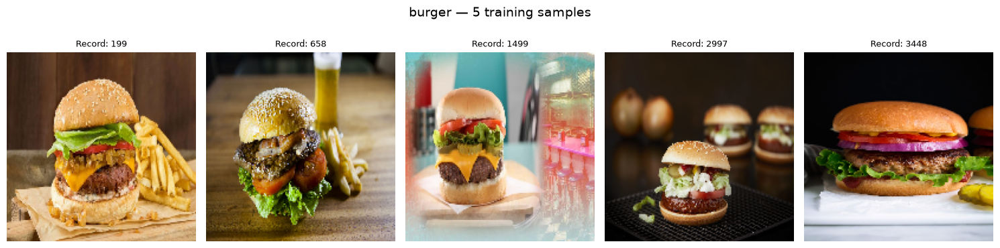

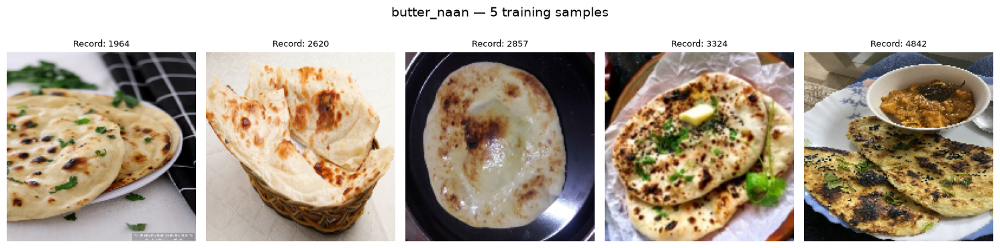

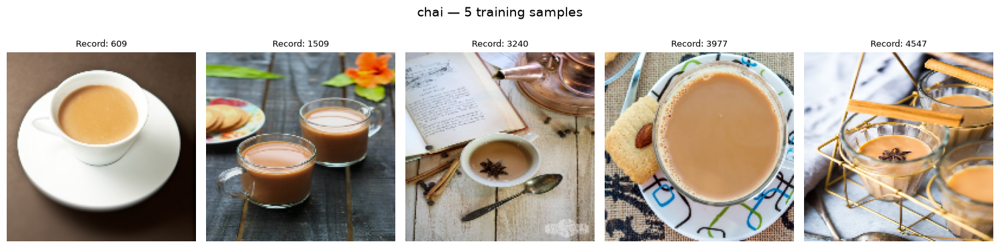

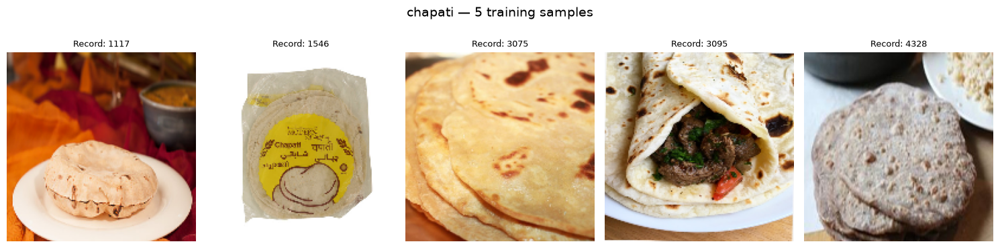

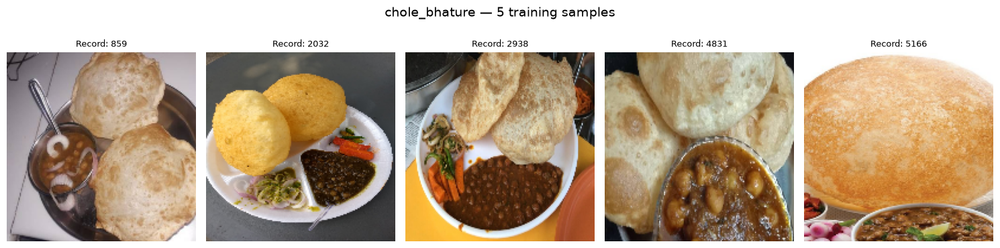

...

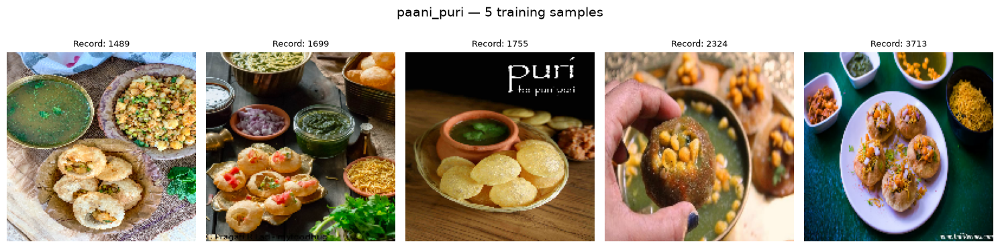

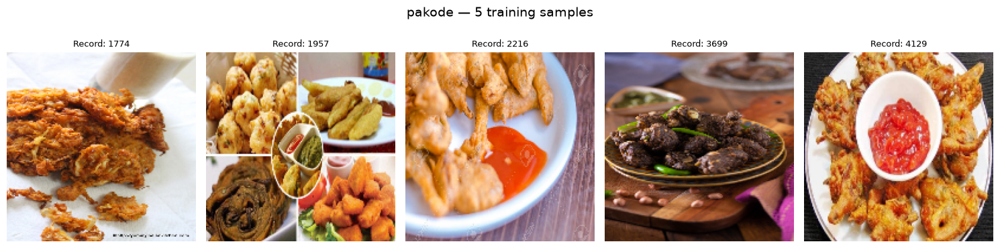

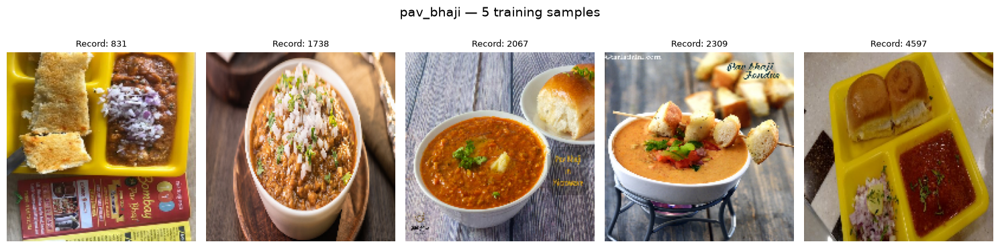

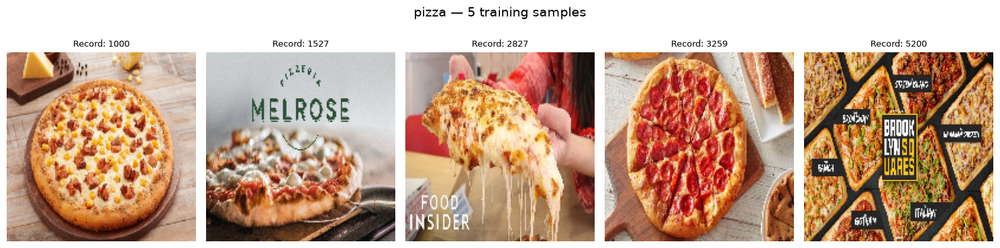

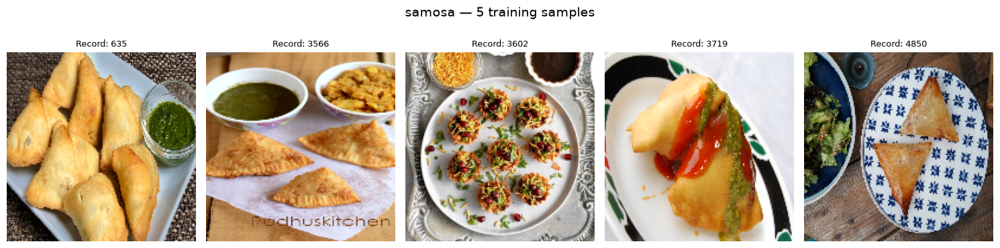

In [39]:

# C27: Display uniform-size sample grids for visual inspection

from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import keras

# Read the selected image records from the training Parquet file.
train_images_df = pd.read_parquet(train_parquet_file, columns=["image"])

# Display-only dimensions; these are not the model input dimensions.
display_size = (160, 160)

for food_class in class_names:
    class_samples = sampled_images_df[
        sampled_images_df["food_class"] == food_class
    ].sort_values("record_index")

    fig, axes = plt.subplots(1, 5, figsize=(15, 4))
    fig.suptitle(f"{food_class} — 5 training samples", fontsize=14)

    for ax, (_, sample) in zip(axes, class_samples.iterrows()):
        record_index = int(sample["record_index"])
        image_bytes = train_images_df.iloc[record_index]["image"]["bytes"]

        # Decode the original image.
        with Image.open(BytesIO(image_bytes)) as img:
            img = img.convert("RGB")
            image_array = np.array(img)

        # Resize a temporary copy for display only.
        display_array = keras.utils.img_to_array(
            keras.utils.array_to_img(
                image_array,
                data_format="channels_last"
            )
        )
        display_array = keras.ops.image.resize(
            display_array,
            size=display_size,
            interpolation="bilinear"
        ).numpy().astype("uint8")

        ax.imshow(display_array)
        ax.set_title(f"Record: {record_index}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


### C29 — Investigate Flagged Images


### Observation — Preliminary Investigation of Flagged Images

- **Pizza (record 5200):** The image depicts pizza but contains numerous text overlays and labels. It is flagged as a potential visual-quality concern rather than a confirmed label error.
- **Momos (record 3827):** The image reportedly shows a packaged momo product. The dish category appears consistent with the package, but the image may be less representative of prepared-food photographs expected from application users.
- **Chapati (record 3095):** The image reportedly shows flatbread being used as a wrap with filling. Its suitability for the plain chapati class is ambiguous and requires further review.
- **Dal makhani (record 4670):** A packaged dal makhani product was reported during inspection. The image should be reviewed for its relevance to the intended prepared-food recognition task.

- **Samosa (record 3602):** The image shows small, round, topped snack pieces that do not clearly resemble conventional samosas. The appearance may be more consistent with another snack, potentially paani puri. The assigned label is therefore flagged as ambiguous and requires further investigation; it is not yet a confirmed label error.


| Food Class | Record Index | Observation | Preliminary Assessment |
|---|---:|---|---|
| Pizza | 5200 | Pizza image contains numerous text overlays and labels. | Visual-quality concern; not a confirmed label error. |
| Momos | 3827 | Image shows a packaged momo product rather than prepared momos. | Potential domain-quality concern; label may be consistent with the package. |
| Chapati | 3095 | Image shows flatbread used as a wrap with filling. | Ambiguous class; requires further review. |
| Dal makhani | 4670 | A packaged dal makhani product was reported during inspection. | Potential domain-quality concern; record index and image require verification. |
| Samosa | 3602 | Small, round, topped snack pieces do not clearly resemble conventional samosas and may resemble another snack. | Possible label ambiguity; requires further investigation. |


**Conclusion:** The preliminary review identifies potential visual-quality and class-ambiguity concerns. These observations do not establish confirmed label errors, so no images are relabelled or excluded at this stage.

**Limitation:** The findings are based on preliminary visual observations. The dal makhani example has not been independently inspected in the images supplied here. Final actions should be recorded in the image-review log after the relevant images are checked.


These findings will feed into the image-review log, C36–C38:
- C36: Consolidate suspicious-image findings.
- C37: Verify flagged labels and investigate the evidence.
- C38: Save an audit of original labels, any approved corrections, reasons, and actions.

____

### Task 6 — Detect exact and near-duplicate images

### C30 — Calculate SHA-256 Hashes

Objective: Generate a SHA-256 hash for every training and test image to identify exact duplicate image bytes. This is the first step in duplicate detection; grouping and checking overlap between splits will be handled in C31.

What we will verify
- All 6,269 images were processed: 5,328 training and 941 test.
- Every image has a 64-character SHA-256 hash.
- The number of unique hashes provides an initial indication of possible exact duplicates.

In [40]:

# C30: Calculate SHA-256 hashes for all images

import hashlib
import pandas as pd
import pyarrow.parquet as pq

parquet_files = {
    "train": train_parquet_file,
    "test": r"G:\AI Project ExcelR\data\images\parquet\data\test-00000-of-00001-899c7c7e401d279b.parquet"
}

hash_records = []
batch_size = 128

for split, parquet_path in parquet_files.items():
    parquet_file = pq.ParquetFile(parquet_path)
    record_index = 0

    for batch in parquet_file.iter_batches(
        batch_size=batch_size,
        columns=["image", "label"]
    ):
        batch_df = batch.to_pandas()

        for _, row in batch_df.iterrows():
            image_bytes = row["image"]["bytes"]

            sha256_hash = hashlib.sha256(image_bytes).hexdigest()

            hash_records.append({
                "split": split,
                "record_index": record_index,
                "label": int(row["label"]),
                "food_class": class_names[int(row["label"])],
                "sha256": sha256_hash
            })

            record_index += 1

    print(f"{split.title()} images hashed: {record_index}")

image_hash_df = pd.DataFrame(hash_records)

# Verify total records and hash format.
print("\nTotal images hashed:", len(image_hash_df))
print("Missing hashes:", image_hash_df["sha256"].isna().sum())
print("Unique SHA-256 hashes:", image_hash_df["sha256"].nunique())
print("Hash length valid:", image_hash_df["sha256"].str.len().eq(64).all())

# Save the hash report for subsequent duplicate analysis.
hash_report_path = (
    r"G:\AI Project ExcelR\outputs\eda\image_sha256_hashes.csv"
)
image_hash_df.to_csv(hash_report_path, index=False)

print("\nHash report saved to:", hash_report_path)
display(image_hash_df.head())


Train images hashed: 5328
Test images hashed: 941

Total images hashed: 6269
Missing hashes: 0
Unique SHA-256 hashes: 6184
Hash length valid: True

Hash report saved to: G:\AI Project ExcelR\outputs\eda\image_sha256_hashes.csv


,split,record_index,label,food_class,sha256
0,train,0,6,dhokla,5eac47e858e85945ceecc1ae1218503d3c79810feb7e4c...
1,train,1,3,chapati,ee896cae9c4bae195a8d3eb466a58ddd78f888f337b968...
2,train,2,11,kadai_paneer,48ddcbdadb1072830744e261419c6d88ce73db0465344b...
3,train,3,16,pakode,7c6727783bea832c0e7541753e858fd615ad20e86b0d9c...
4,train,4,1,butter_naan,170f5af0706224eca152faba4f27fc1547c5bb0758258f...


In [41]:
6269-6184

85


### Observation — SHA-256 Hash Calculation

- SHA-256 hashes were calculated for all 6,269 images: 5,328 training images and 941 test images.
- No missing hashes were reported, and all generated hashes passed the 64-character length check.
- The dataset contains 6,184 unique SHA-256 hashes.
- The difference between total records and unique hashes is 85, indicating 85 excess records associated with repeated hashes.

**Conclusion:** The results indicate potential exact duplicates at the byte level. Further grouping is required to identify duplicate groups and determine whether they occur within or across the training and test splits.

**Limitation:** The total of 85 excess records does not represent 85 confirmed duplicate pairs. No images have been deleted or modified.


### C31 — Group exact duplicates
This will give us the evidence needed to interpret the 85 excess records correctly.

In [42]:

# C31 — Identify exact duplicate images using SHA-256 hashes

# Group images that have identical SHA-256 hashes
duplicate_hashes_df = (
    image_hash_df
    .groupby("sha256")
    .agg(
        occurrence_count=("sha256", "size"),
        splits=("split", lambda x: ", ".join(sorted(set(x)))),
        class_count=("food_class", "nunique"),
        classes=("food_class", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
)

# Keep only hashes that occur more than once
duplicate_groups_df = (
    duplicate_hashes_df[
        duplicate_hashes_df["occurrence_count"] > 1
    ]
    .sort_values(
        ["occurrence_count", "sha256"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

# Retrieve every record belonging to a repeated hash
duplicate_records_df = (
    image_hash_df[
        image_hash_df["sha256"].isin(duplicate_groups_df["sha256"])
    ]
    .sort_values(["sha256", "split", "record_index"])
    .reset_index(drop=True)
)

# Summarise duplicate findings
total_duplicate_groups = len(duplicate_groups_df)
records_in_duplicate_groups = len(duplicate_records_df)
excess_duplicate_records = int(
    (duplicate_groups_df["occurrence_count"] - 1).sum()
)

cross_split_groups = int(
    duplicate_groups_df["splits"].str.contains(",", regex=False).sum()
)

label_mismatch_groups = int(
    (duplicate_groups_df["class_count"] > 1).sum()
)

print("EXACT DUPLICATE ANALYSIS")
print("-" * 40)
print(f"Total image records: {len(image_hash_df)}")
print(f"Unique SHA-256 hashes: {image_hash_df['sha256'].nunique()}")
print(f"Repeated-hash groups: {total_duplicate_groups}")
print(f"Records in repeated-hash groups: {records_in_duplicate_groups}")
print(f"Excess records beyond one per group: {excess_duplicate_records}")
print(f"Groups spanning train and test: {cross_split_groups}")
print(f"Groups with different food labels: {label_mismatch_groups}")

print("\nRepeated-hash group details:")
display(duplicate_groups_df.head(20))

# print("\nAll records belonging to repeated hashes:")
# display(duplicate_records_df.head(30))

# Save reports for detailed review
duplicate_groups_path = (
    r"G:\AI Project ExcelR\outputs\eda\exact_duplicate_groups.csv"
)
duplicate_records_path = (
    r"G:\AI Project ExcelR\outputs\eda\exact_duplicate_records.csv"
)

duplicate_groups_df.to_csv(duplicate_groups_path, index=False)
duplicate_records_df.to_csv(duplicate_records_path, index=False)

print("\nReports saved:")
print(duplicate_groups_path)
print(duplicate_records_path)


EXACT DUPLICATE ANALYSIS
----------------------------------------
Total image records: 6269
Unique SHA-256 hashes: 6184
Repeated-hash groups: 85
Records in repeated-hash groups: 170
Excess records beyond one per group: 85
Groups spanning train and test: 25
Groups with different food labels: 1

Repeated-hash group details:


,sha256,occurrence_count,splits,class_count,classes
0,010dd2fba5a9182f9dcfdbb3d3c3d7b8858bdd89cdfcab...,2,train,1,momos
1,03f1c75d936ce294732c9d6e3b63343ee3e4a5af91ebea...,2,train,1,masala_dosa
2,090a5e7785604cdf17bbd8cdbd5a588d7feb7c5cc90e36...,2,"test, train",1,momos
3,140901088b521f326216a3a7b289cd5c4878602df1f2f2...,2,train,1,dal_makhani
4,178fccce5c3d686abf710c477d26e47dc8c5b67839f2a3...,2,"test, train",1,kulfi
5,205576996ca5e48c23e326d23f57d656fad501c782c803...,2,train,1,pakode
6,227267620bbdd788adca75530d9fb503b70c436bd7d0b3...,2,"test, train",1,dal_makhani
7,26c555dea9f4da78f2c2c71804c88aeef52d860023a053...,2,train,1,chole_bhature
8,2b4244ac1946601d4693ddd3726094db6ee7ed86d5e447...,2,train,1,kadai_paneer
9,2c064072cfc037b0876b69bb827449fe277ce23dd32340...,2,"test, train",1,dhokla



Reports saved:
G:\AI Project ExcelR\outputs\eda\exact_duplicate_groups.csv
G:\AI Project ExcelR\outputs\eda\exact_duplicate_records.csv


### Inconsistent Image for same label name 

In [43]:

# C31 follow-up — Inspect repeated images with inconsistent labels

label_mismatch_hashes = duplicate_groups_df.loc[
    duplicate_groups_df["class_count"] > 1, "sha256"
]

label_mismatch_records_df = (
    image_hash_df[
        image_hash_df["sha256"].isin(label_mismatch_hashes)
    ]
    .sort_values(["sha256", "split", "record_index"])
    .reset_index(drop=True)
)

print("Number of inconsistent-label hash groups:", len(label_mismatch_hashes))
print("Number of records in these groups:", len(label_mismatch_records_df))

display(
    label_mismatch_records_df[
        ["sha256", "split", "record_index", "label", "food_class"]
    ]
)


Number of inconsistent-label hash groups: 1
Number of records in these groups: 2


,sha256,split,record_index,label,food_class
0,8b4eb95b572aa48716f70d5ccecc4a45910284a264b691...,test,314,1,butter_naan
1,8b4eb95b572aa48716f70d5ccecc4a45910284a264b691...,train,2422,11,kadai_paneer


### C32 — Calculate Perceptual Hashes

We'll calculate pHash values for all 6,269 images and save the results. We'll use the installed ImageHash and Pillow libraries, and we'll keep the original images unchanged.

In C31, we found exact duplicates by comparing SHA-256 hashes. However, two images can look almost identical while having different file bytes—for example, if one image has been resized, compressed, or slightly edited.

A perceptual hash (pHash) creates a fingerprint based on an image's visual appearance. It helps us find candidates for near-duplicates.

In [44]:

# C32 — Calculate perceptual hashes for all images

import io
import pandas as pd
import pyarrow.parquet as pq
from PIL import Image
import imagehash

parquet_files = {
    "train": train_parquet_file,
    "test": r"G:\AI Project ExcelR\data\images\parquet\data\test-00000-of-00001-899c7c7e401d279b.parquet"
}

phash_records = []

for split, parquet_path in parquet_files.items():
    parquet_file = pq.ParquetFile(parquet_path)
    record_index = 0

    for batch in parquet_file.iter_batches(
        batch_size=128,
        columns=["image", "label"]
    ):
        batch_df = batch.to_pandas()

        for _, row in batch_df.iterrows():
            image_bytes = row["image"]["bytes"]

            with Image.open(io.BytesIO(image_bytes)) as image:
                phash_value = str(imagehash.phash(image.convert("RGB")))

            label_id = int(row["label"])

            phash_records.append({
                "split": split,
                "record_index": record_index,
                "label": label_id,
                "food_class": class_names[label_id],
                "phash": phash_value
            })

            record_index += 1

    print(f"{split.title()} images processed: {record_index}")

# Create a DataFrame of perceptual hashes
image_phash_df = pd.DataFrame(phash_records)

print("\nPERCEPTUAL HASH SUMMARY")
print("-" * 40)
print(f"Total records processed: {len(image_phash_df)}")
print(f"Missing perceptual hashes: {image_phash_df['phash'].isna().sum()}")
print(f"Unique perceptual hashes: {image_phash_df['phash'].nunique()}")
print(
    "Hash length valid:",
    image_phash_df["phash"].str.len().eq(16).all()
)

# Save the perceptual hash report
phash_report_path = (
    r"G:\AI Project ExcelR\outputs\eda\image_perceptual_hashes.csv"
)
image_phash_df.to_csv(phash_report_path, index=False)

print(f"\nPerceptual hash report saved to: {phash_report_path}")
display(image_phash_df.head())


Train images processed: 5328
Test images processed: 941

PERCEPTUAL HASH SUMMARY
----------------------------------------
Total records processed: 6269
Missing perceptual hashes: 0
Unique perceptual hashes: 6174
Hash length valid: True

Perceptual hash report saved to: G:\AI Project ExcelR\outputs\eda\image_perceptual_hashes.csv


,split,record_index,label,food_class,phash
0,train,0,6,dhokla,81f07a032d7fd4ac
1,train,1,3,chapati,fb31045c5f705c6a
2,train,2,11,kadai_paneer,b943d31f0e3c4a69
3,train,3,16,pakode,9bd1d494a825653f
4,train,4,1,butter_naan,81877978e027cfc6


In [45]:
6269-6174

95


### Observation — C32: Perceptual Hash Calculation

- Perceptual hashes were calculated for all 6,269 image records: 5,328 training records and 941 test records.
- No missing perceptual hashes were reported, and all hashes passed the expected 16-character length check.
- The dataset produced 6,174 unique perceptual hash values.
- The difference between total records and unique hash values is 95, indicating excess records associated with repeated hash values.
- The report was saved to `G:\AI Project ExcelR\outputs\eda\image_perceptual_hashes.csv`.

**Conclusion:** Perceptual hashing completed successfully, and the generated fingerprints are ready for similarity analysis in C33.

**Limitation:** The 95 excess records are not confirmed near-duplicates. Perceptual hash matches must be compared using Hamming distance and reviewed before drawing conclusions. No images have been deleted or modified.


### C33 — Compare perceptual hashes using Hamming distance

Purpose: Identify pairs of images whose perceptual hashes are identical or sufficiently similar to warrant visual review. We'll use an initial candidate threshold of Hamming distance ≤ 8 out of 64 bits. This is a screening threshold, not proof that two images are duplicates.

In [46]:

import numpy as np
import pandas as pd

PHASH_THRESHOLD = 8
CHUNK_SIZE = 128

# Validate the outputs from C30 and C32.
required_hash_columns = {"split", "record_index", "sha256"}
required_phash_columns = {
    "split", "record_index", "label", "food_class", "phash"
}

assert required_hash_columns.issubset(image_hash_df.columns), (
    f"Missing C30 columns: "
    f"{required_hash_columns - set(image_hash_df.columns)}"
)

assert required_phash_columns.issubset(image_phash_df.columns), (
    f"Missing C32 columns: "
    f"{required_phash_columns - set(image_phash_df.columns)}"
)

record_keys = ["split", "record_index"]

assert not image_hash_df.duplicated(record_keys).any()
assert not image_phash_df.duplicated(record_keys).any()

sha_lookup = image_hash_df.set_index(record_keys)["sha256"]

phash_values = image_phash_df["phash"].astype(str)

assert phash_values.str.fullmatch(r"[0-9a-fA-F]{16}").all(), (
    "Some pHashes are not valid 16-character hexadecimal values."
)

hash_ints = np.array(
    [int(value, 16) for value in phash_values],
    dtype=np.uint64
)

metadata = image_phash_df[
    ["split", "record_index", "label", "food_class", "phash"]
].reset_index(drop=True)

num_images = len(metadata)
candidate_records = []

# Compare images in chunks to limit memory use.
for start in range(0, num_images, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, num_images)

    xor_values = np.bitwise_xor(
        hash_ints[start:end, None],
        hash_ints[None, :]
    )

    xor_bytes = xor_values.view(np.uint8).reshape(
        end - start, num_images, 8
    )
    distances = np.unpackbits(xor_bytes, axis=2).sum(axis=2)

    # Keep each pair once and exclude self-comparisons.
    local_positions, other_positions = np.where(
        (distances <= PHASH_THRESHOLD)
        & (
            np.arange(start, end)[:, None]
            < np.arange(num_images)[None, :]
        )
    )

    for local_position, other_position in zip(
        local_positions, other_positions
    ):
        left_position = start + int(local_position)
        right_position = int(other_position)

        left = metadata.iloc[left_position]
        right = metadata.iloc[right_position]

        left_key = (left["split"], int(left["record_index"]))
        right_key = (right["split"], int(right["record_index"]))

        candidate_records.append({
            "split_1": left["split"],
            "record_index_1": int(left["record_index"]),
            "label_1": int(left["label"]),
            "food_class_1": left["food_class"],
            "phash_1": left["phash"],
            "split_2": right["split"],
            "record_index_2": int(right["record_index"]),
            "label_2": int(right["label"]),
            "food_class_2": right["food_class"],
            "phash_2": right["phash"],
            "hamming_distance": int(
                distances[local_position, other_position]
            ),
            "same_split": left["split"] == right["split"],
            "same_label": int(left["label"]) == int(right["label"]),
            "exact_sha256_match": (
                sha_lookup.loc[left_key] == sha_lookup.loc[right_key]
            )
        })

    print(f"Compared records {start + 1}–{end} of {num_images}")

candidate_columns = [
    "split_1", "record_index_1", "label_1", "food_class_1", "phash_1",
    "split_2", "record_index_2", "label_2", "food_class_2", "phash_2",
    "hamming_distance", "same_split", "same_label", "exact_sha256_match"
]

phash_candidates_df = pd.DataFrame(
    candidate_records, columns=candidate_columns
).sort_values(
    ["hamming_distance", "split_1", "record_index_1",
     "split_2", "record_index_2"]
).reset_index(drop=True)

print("\nC33 — Perceptual Hash Comparison Summary")
print("-" * 45)
print(f"Image records compared: {num_images}")
print(f"Hamming distance threshold: <= {PHASH_THRESHOLD} / 64 bits")
print(f"Candidate pairs found: {len(phash_candidates_df)}")
print(
    "Identical pHash pairs (distance 0): "
    f"{(phash_candidates_df['hamming_distance'] == 0).sum()}"
)
print(
    "Candidate pairs with identical SHA-256: "
    f"{phash_candidates_df['exact_sha256_match'].sum()}"
)
print(
    "Candidate pairs across train and test: "
    f"{(~phash_candidates_df['same_split']).sum()}"
)
print(
    "Candidate pairs with different food labels: "
    f"{(~phash_candidates_df['same_label']).sum()}"
)

print("\nCandidate pairs by Hamming distance:")
if phash_candidates_df.empty:
    print("No candidate pairs found at this threshold.")
else:
    print(
        phash_candidates_df["hamming_distance"]
        .value_counts()
        .sort_index()
        .to_string()
    )

print("\nFirst 20 candidate pairs:")
display(phash_candidates_df.head(20))

candidate_report_path = (
    r"G:\AI Project ExcelR\outputs\eda\perceptual_hash_candidates.csv"
)
phash_candidates_df.to_csv(candidate_report_path, index=False)

print(f"\nCandidate report saved to: {candidate_report_path}")


Compared records 1–128 of 6269
Compared records 129–256 of 6269
Compared records 257–384 of 6269
Compared records 385–512 of 6269
Compared records 513–640 of 6269
Compared records 641–768 of 6269
Compared records 769–896 of 6269
Compared records 897–1024 of 6269
Compared records 1025–1152 of 6269
Compared records 1153–1280 of 6269
Compared records 1281–1408 of 6269
Compared records 1409–1536 of 6269
Compared records 1537–1664 of 6269
Compared records 1665–1792 of 6269
Compared records 1793–1920 of 6269
Compared records 1921–2048 of 6269
Compared records 2049–2176 of 6269
Compared records 2177–2304 of 6269
Compared records 2305–2432 of 6269
Compared records 2433–2560 of 6269
Compared records 2561–2688 of 6269
Compared records 2689–2816 of 6269
Compared records 2817–2944 of 6269
Compared records 2945–3072 of 6269
Compared records 3073–3200 of 6269
Compared records 3201–3328 of 6269
Compared records 3329–3456 of 6269
Compared records 3457–3584 of 6269
Compared records 3585–3712 of 6269
Co

,split_1,record_index_1,label_1,food_class_1,phash_1,split_2,record_index_2,label_2,food_class_2,phash_2,hamming_distance,same_split,same_label,exact_sha256_match
0,test,195,4,chole_bhature,8a6e3ee800bdf8c3,test,465,4,chole_bhature,8a6e3ee800bdf8c3,0,True,True,True
1,train,30,14,momos,8261e9937a59e19e,train,4413,14,momos,8261e9937a59e19e,0,True,True,True
2,train,95,10,kaathi_rolls,d0092f8b8d7728ed,train,1137,10,kaathi_rolls,d0092f8b8d7728ed,0,True,True,True
3,train,116,18,pizza,978916d42b87bf42,train,1688,18,pizza,978916d42b87bf42,0,True,True,False
4,train,120,12,kulfi,fda8cbc794983630,test,374,12,kulfi,fda8cbc794983630,0,False,True,True
5,train,158,10,kaathi_rolls,a9d10ed669c825d7,train,2178,10,kaathi_rolls,a9d10ed669c825d7,0,True,True,True
6,train,167,17,pav_bhaji,ea9546ee9561838d,train,918,17,pav_bhaji,ea9546ee9561838d,0,True,True,True
7,train,176,19,samosa,e9194aed3a923b92,train,4676,19,samosa,e9194aed3a923b92,0,True,True,True
8,train,183,5,dal_makhani,c6e664d49c2b2d69,test,101,5,dal_makhani,c6e664d49c2b2d69,0,False,True,True
9,train,198,12,kulfi,8cdc3ce4558d6297,train,1542,12,kulfi,8cdc3ce4558d6297,0,True,True,True



Candidate report saved to: G:\AI Project ExcelR\outputs\eda\perceptual_hash_candidates.csv



### Observation — C33: Perceptual Hash Comparison

- Perceptual hashes were compared for all 6,269 image records using an initial Hamming distance threshold of **8 out of 64 bits**.
- The comparison identified **99 candidate pairs**: 95 pairs had identical perceptual hashes (distance 0), while four pairs had nonzero distances (two at distance 6 and two at distance 8).
- **85 candidate pairs** also had identical SHA-256 hashes, confirming exact byte-for-byte duplicates consistent with C31.
- **29 candidate pairs** spanned the training and test sets, indicating potential data leakage that requires review.
- **Two candidate pairs** had different food labels and require investigation.
- The complete candidate report was saved to `G:\AI Project ExcelR\outputs\eda\perceptual_hash_candidates.csv`.

**Conclusion:** C33 identified exact duplicates, additional perceptual-hash matches, possible train–test leakage, and label inconsistencies for further investigation in C34.

**Limitation:** Perceptual-hash matches do not automatically confirm visual duplicates. The remaining candidates require image inspection, and the correct labels for conflicting records must be verified. No images have been deleted, relabelled, or reassigned.



### C34 — Review duplicate candidates

In C34, we will review the candidate report and connect it with your five manually flagged images from C29. We will not assume those five images must appear in the hash report to remain under investigation.

Our review will distinguish:

1. Confirmed exact duplicates.
2. Visually similar but different images.
3. Conflicting labels.
4. Train–test leakage.
5. Unresolved candidates.

We will keep the original dataset unchanged and document decisions before making any corrections.

In [47]:

import pandas as pd

# Confirm that the C33 candidate results are available.
assert "phash_candidates_df" in globals(), (
    "C33 results are unavailable. Run C33 successfully before C34."
)

required_columns = {
    "split_1", "record_index_1", "label_1", "food_class_1",
    "split_2", "record_index_2", "label_2", "food_class_2",
    "hamming_distance", "same_split", "same_label",
    "exact_sha256_match"
}

assert required_columns.issubset(phash_candidates_df.columns), (
    f"C33 results are missing columns: "
    f"{required_columns - set(phash_candidates_df.columns)}"
)

# Create a reviewable copy; do not modify the original candidate report.
c34_review_df = phash_candidates_df.copy()

c34_review_df.insert(
    0, "candidate_id",
    [f"PHASH_{i:03d}" for i in range(1, len(c34_review_df) + 1)]
)

# Prioritize cross-split pairs, label conflicts, and non-identical pHashes.
c34_review_df["review_priority"] = "Standard"

c34_review_df.loc[
    ~c34_review_df["same_split"], "review_priority"
] = "High - train/test overlap"

c34_review_df.loc[
    ~c34_review_df["same_label"], "review_priority"
] = "High - label conflict"

c34_review_df.loc[
    (~c34_review_df["same_split"]) & (~c34_review_df["same_label"]),
    "review_priority"
] = "Urgent - overlap and label conflict"

c34_review_df.loc[
    c34_review_df["hamming_distance"] > 0, "review_priority"
] = "Review visual similarity"

c34_review_df.loc[
    (~c34_review_df["same_split"])
    & (c34_review_df["hamming_distance"] > 0),
    "review_priority"
] = "High - cross-split visual similarity"

c34_review_df.loc[
    (~c34_review_df["same_label"])
    & (c34_review_df["hamming_distance"] > 0),
    "review_priority"
] = "High - visual similarity and label conflict"

c34_review_df.loc[
    (~c34_review_df["same_split"])
    & (~c34_review_df["same_label"])
    & (c34_review_df["hamming_distance"] > 0),
    "review_priority"
] = "Urgent - overlap, similarity and label conflict"

# Keep all decisions pending until visual inspection is completed.
c34_review_df["review_status"] = "Pending"
c34_review_df["visual_review_notes"] = ""
c34_review_df["review_decision"] = "Pending"
c34_review_df["proposed_action"] = "Undecided"

# Save a separate review log; keep the C33 report unchanged.
c34_review_path = (
    r"G:\AI Project ExcelR\outputs\eda\perceptual_hash_review_log.csv"
)
c34_review_df.to_csv(c34_review_path, index=False)

print("C34 — Candidate Review Log")
print("-" * 40)
print(f"Candidate pairs in review log: {len(c34_review_df)}")
print(
    "Exact SHA-256 duplicate pairs: "
    f"{c34_review_df['exact_sha256_match'].sum()}"
)
print(
    "Pairs spanning train and test: "
    f"{(~c34_review_df['same_split']).sum()}"
)
print(
    "Pairs with different food labels: "
    f"{(~c34_review_df['same_label']).sum()}"
)
print(
    "Pairs with nonzero Hamming distance: "
    f"{(c34_review_df['hamming_distance'] > 0).sum()}"
)

print("\nReview priority counts:")
print(c34_review_df["review_priority"].value_counts().to_string())

print("\nPairs requiring priority attention:")
display(
    c34_review_df[
        (~c34_review_df["same_split"])
        | (~c34_review_df["same_label"])
        | (c34_review_df["hamming_distance"] > 0)
    ].head(25)
)

print(f"\nReview log saved to: {c34_review_path}")
print("All review decisions remain Pending.")


C34 — Candidate Review Log
----------------------------------------
Candidate pairs in review log: 99
Exact SHA-256 duplicate pairs: 85
Pairs spanning train and test: 29
Pairs with different food labels: 2
Pairs with nonzero Hamming distance: 4

Review priority counts:
review_priority
Standard                                       67
High - train/test overlap                      27
Review visual similarity                        2
Urgent - overlap and label conflict             1
High - cross-split visual similarity            1
High - visual similarity and label conflict     1

Pairs requiring priority attention:


,candidate_id,split_1,record_index_1,label_1,food_class_1,phash_1,split_2,record_index_2,label_2,food_class_2,phash_2,hamming_distance,same_split,same_label,exact_sha256_match,review_priority,review_status,visual_review_notes,review_decision,proposed_action
4,PHASH_005,train,120,12,kulfi,fda8cbc794983630,test,374,12,kulfi,fda8cbc794983630,0,False,True,True,High - train/test overlap,Pending,,Pending,Undecided
8,PHASH_009,train,183,5,dal_makhani,c6e664d49c2b2d69,test,101,5,dal_makhani,c6e664d49c2b2d69,0,False,True,True,High - train/test overlap,Pending,,Pending,Undecided
13,PHASH_014,train,280,3,chapati,ea173a174257475a,test,40,3,chapati,ea173a174257475a,0,False,True,True,High - train/test overlap,Pending,,Pending,Undecided
17,PHASH_018,train,433,14,momos,c27438f26319db2d,test,793,14,momos,c27438f26319db2d,0,False,True,True,High - train/test overlap,Pending,,Pending,Undecided
21,PHASH_022,train,551,6,dhokla,cda62b9990dae788,test,228,6,dhokla,cda62b9990dae788,0,False,True,True,High - train/test overlap,Pending,,Pending,Undecided
23,PHASH_024,train,568,5,dal_makhani,bdd8d6ea294c151a,test,785,5,dal_makhani,bdd8d6ea294c151a,0,False,True,True,High - train/test overlap,Pending,,Pending,Undecided
31,PHASH_032,train,858,19,samosa,916b5c667ad368b0,test,150,19,samosa,916b5c667ad368b0,0,False,True,True,High - train/test overlap,Pending,,Pending,Undecided
34,PHASH_035,train,977,13,masala_dosa,856f40da179e70f8,test,408,13,masala_dosa,856f40da179e70f8,0,False,True,True,High - train/test overlap,Pending,,Pending,Undecided
35,PHASH_036,train,1007,5,dal_makhani,df91603cb0b3c3c3,test,786,5,dal_makhani,df91603cb0b3c3c3,0,False,True,True,High - train/test overlap,Pending,,Pending,Undecided
36,PHASH_037,train,1013,3,chapati,d5a95214bcb3d24d,test,887,3,chapati,d5a95214bcb3d24d,0,False,True,True,High - train/test overlap,Pending,,Pending,Undecided



Review log saved to: G:\AI Project ExcelR\outputs\eda\perceptual_hash_review_log.csv
All review decisions remain Pending.



### C34 — Candidate Review Log: Summary

| Output | Count | Simple meaning |
|---|---:|---|
| Candidate pairs in review log | 99 | Image pairs identified for review using the perceptual-hash screening threshold. |
| Exact SHA-256 duplicate pairs | 85 | Pairs containing identical image bytes. |
| Pairs spanning train and test | 29 | Pairs appearing across training and test sets, creating potential data-leakage risk. |
| Pairs with different food labels | 2 | Pairs whose images have different assigned food labels and require investigation. |
| Pairs with nonzero Hamming distance | 4 | Pairs with similar but non-identical perceptual hashes that require visual review. |



### C34 — Step 2: Visually inspect the conflicting-label pair

Training record 2422 assigned label: kadai_paneer
Test record 314 assigned label: butter_naan


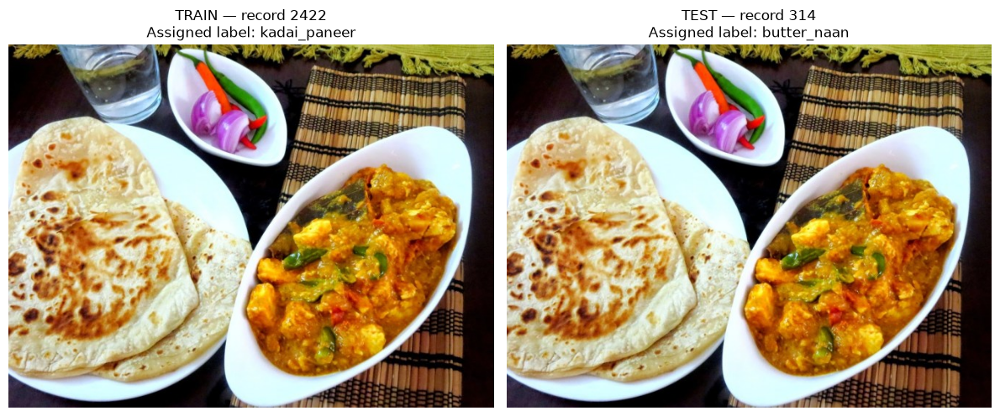

In [48]:

import io
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from PIL import Image

# Use the established dataset paths.
c34_parquet_paths = {
    "train": train_parquet_file,
    "test": (
        r"G:\AI Project ExcelR\data\images\parquet\data"
        r"\test-00000-of-00001-899c7c7e401d279b.parquet"
    )
}

def c34_load_image(split, target_index, batch_size=128):
    """Load one original image by its split-relative record index."""
    parquet_file = pq.ParquetFile(c34_parquet_paths[split])
    start_index = 0

    for batch in parquet_file.iter_batches(
        batch_size=batch_size, columns=["image", "label"]
    ):
        batch_length = batch.num_rows

        if start_index <= target_index < start_index + batch_length:
            row = batch.slice(target_index - start_index, 1).to_pylist()[0]
            image_bytes = row["image"]["bytes"]
            image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
            return image, int(row["label"])

        start_index += batch_length

    raise IndexError(
        f"Record index {target_index} was not found in {split}."
    )

# The conflicting-label pair identified in C31-C34.
image_train, label_train = c34_load_image("train", 2422)
image_test, label_test = c34_load_image("test", 314)

print("Training record 2422 assigned label:", class_names[label_train])
print("Test record 314 assigned label:", class_names[label_test])

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(image_train)
axes[0].set_title(
    f"TRAIN — record 2422\nAssigned label: {class_names[label_train]}"
)
axes[0].axis("off")

axes[1].imshow(image_test)
axes[1].set_title(
    f"TEST — record 314\nAssigned label: {class_names[label_test]}"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()


### C34 — Step 3: Inspect the next cross-split candidates

The conflicting-label pair has been reviewed.

Next, let's inspect PHASH_097, which has a nonzero Hamming distance of 6 and appears across the training and test sets:
- Training record 5277 — butter_naan
- Test record 242 — butter_naan
These images have the same assigned label but different SHA-256 hashes. We need to see whether they are visually similar versions of the same image or simply different images of butter naan.

Candidate: PHASH_097
Image 1: train record 5277 — butter_naan
Image 2: test record 242 — butter_naan
Hamming distance: 6
Exact SHA-256 match: False


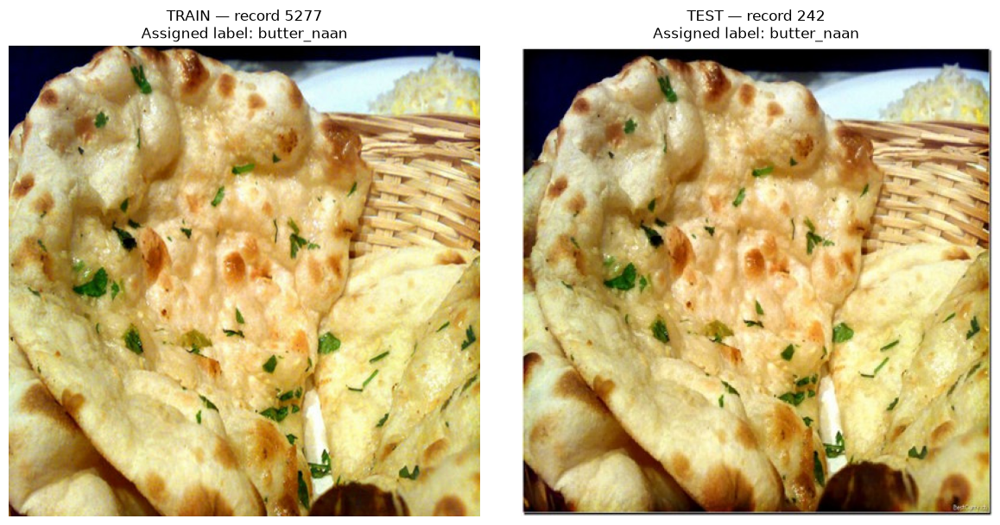

In [49]:

# C34 — Step 3: Inspect PHASH_097

candidate_id = "PHASH_097"

candidate = c34_review_df.loc[
    c34_review_df["candidate_id"] == candidate_id
]

assert len(candidate) == 1, (
    f"Expected exactly one row for {candidate_id}; found {len(candidate)}."
)

row = candidate.iloc[0]

image_train, label_train = c34_load_image(
    row["split_1"], int(row["record_index_1"])
)
image_test, label_test = c34_load_image(
    row["split_2"], int(row["record_index_2"])
)

print(f"Candidate: {candidate_id}")
print(
    f"Image 1: {row['split_1']} record {int(row['record_index_1'])} "
    f"— {class_names[label_train]}"
)
print(
    f"Image 2: {row['split_2']} record {int(row['record_index_2'])} "
    f"— {class_names[label_test]}"
)
print(f"Hamming distance: {int(row['hamming_distance'])}")
print(f"Exact SHA-256 match: {bool(row['exact_sha256_match'])}")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(image_train)
axes[0].set_title(
    f"{row['split_1'].upper()} — record {int(row['record_index_1'])}\n"
    f"Assigned label: {class_names[label_train]}"
)
axes[0].axis("off")

axes[1].imshow(image_test)
axes[1].set_title(
    f"{row['split_2'].upper()} — record {int(row['record_index_2'])}\n"
    f"Assigned label: {class_names[label_test]}"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()



### Observation — C34, Step 3: Review of PHASH_097

- Training record **5277** and test record **242** are both labelled `butter_naan`.
- The pair has a Hamming distance of **6 out of 64 bits**, which falls within the C33 candidate threshold of 8.
- Their SHA-256 hashes differ, so they are not exact byte-for-byte duplicates.
- Visual inspection shows nearly identical naan arrangements, toppings, and backgrounds. The images are likely duplicate or near-duplicate versions of the same photograph.
- Because the pair spans training and test sets, it may introduce data leakage and should be reviewed before final model evaluation.

**Conclusion:** PHASH_097 is a strong visual near-duplicate candidate across the training and test sets.

**Limitation:** The original source relationship has not been independently verified. No images have been removed or modified.


### Task 1 — Step 1: Display the five flagged images together

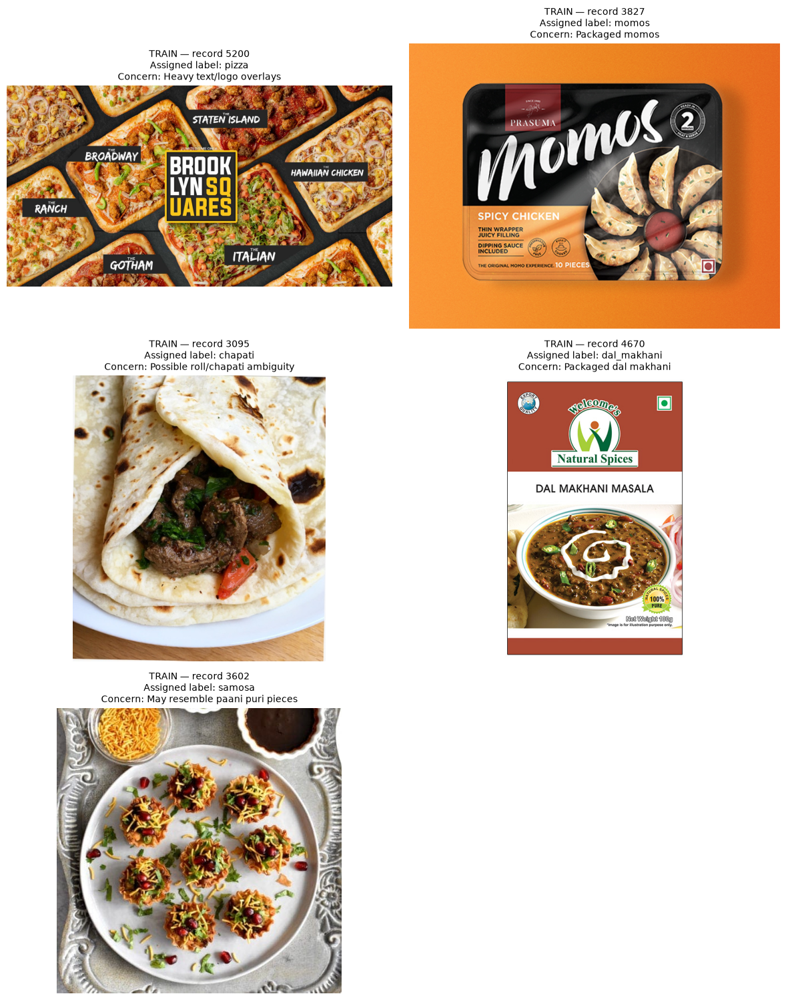

C29 records loaded: 5

Verified record labels:


,record_index,assigned_class,initial_concern
0,5200,pizza,Heavy text/logo overlays
1,3827,momos,Packaged momos
2,3095,chapati,Possible roll/chapati ambiguity
3,4670,dal_makhani,Packaged dal makhani
4,3602,samosa,May resemble paani puri pieces


In [50]:

# Task 1 — C29: Revisit the five manually flagged images

c29_flagged_records = [
    {"record_index": 5200, "expected_class": "pizza",
     "initial_concern": "Heavy text/logo overlays"},
    {"record_index": 3827, "expected_class": "momos",
     "initial_concern": "Packaged momos"},
    {"record_index": 3095, "expected_class": "chapati",
     "initial_concern": "Possible roll/chapati ambiguity"},
    {"record_index": 4670, "expected_class": "dal_makhani",
     "initial_concern": "Packaged dal makhani"},
    {"record_index": 3602, "expected_class": "samosa",
     "initial_concern": "May resemble paani puri pieces"}
]

fig, axes = plt.subplots(3, 2, figsize=(12, 15))
axes = axes.flatten()

c29_review_results = []

for position, item in enumerate(c29_flagged_records):
    record_index = item["record_index"]

    image, actual_label_id = c34_load_image("train", record_index)
    actual_class = class_names[actual_label_id]

    c29_review_results.append({
        "split": "train",
        "record_index": record_index,
        "assigned_class": actual_class,
        "initial_concern": item["initial_concern"],
        "review_status": "Pending",
        "review_decision": "Pending",
        "review_notes": ""
    })

    axes[position].imshow(image)
    axes[position].set_title(
        f"TRAIN — record {record_index}\n"
        f"Assigned label: {actual_class}\n"
        f"Concern: {item['initial_concern']}",
        fontsize=10
    )
    axes[position].axis("off")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

c29_review_df = pd.DataFrame(c29_review_results)

print("C29 records loaded:", len(c29_review_df))
print("\nVerified record labels:")
display(
    c29_review_df[
        ["record_index", "assigned_class", "initial_concern"]
    ]
)


### Task 2 — Step 1: Build the exact train–test duplicate action report
Groups records by SHA-256 hash, identifies the exact duplicates spanning training and test, checks assigned-label consistency, and recommends a documented action for each group.


### Observation — Task 2: Exact Train–Test Duplicate Resolution

- SHA-256 analysis identified **25 exact-duplicate groups** spanning the training and test sets.
- These groups contain 25 training records and 25 test records.
- **24 groups have consistent food labels** and are candidates for removing the training copies from the future modelling dataset while retaining the test copies.
- **One group has conflicting labels:** training record 2422 is labelled `kadai_paneer`, while test record 314 is labelled `butter_naan`. Visual inspection showed that the identical photograph contains multiple food items, so the correct action requires a documented dataset-suitability decision.
- The action report was saved to `G:\AI Project ExcelR\outputs\eda\exact_train_test_duplicate_actions.csv`.

**Conclusion:** The exact train–test duplicates have been identified programmatically, and proposed actions have been recorded for all 25 groups.

**Limitation:** The report records proposed actions; no images have been deleted or modified. The conflicting-label group remains unresolved, and the recommendations must be applied to a separate modelling dataset before final evaluation.


### Task 3 — Step 1: Build the consolidated action log

### C36 — Consolidate suspicious-image findings

Objective: Combine our existing manual-review, exact-duplicate, and perceptual-hash findings into one consolidated list. We will reuse the reports already generated rather than repeat the analysis.

This cell will:
- Load the existing review and duplicate reports.
- Consolidate the flagged records and their reasons.
- Save a report for the next step, C37.
- Leave the original Parquet files and test dataset unchanged.

In [51]:

# C36 — Consolidate suspicious-image findings

from pathlib import Path
import pandas as pd

# Existing project output directory
output_dir = Path(r"G:\AI Project ExcelR\outputs\eda")

# Existing reports created in earlier cells
report_files = {
    "manual_review": output_dir / "image_review_log.csv",
    "exact_duplicates": output_dir / "exact_duplicate_groups.csv",
    "exact_duplicate_actions": output_dir / "exact_train_test_duplicate_actions.csv",
    "perceptual_candidates": output_dir / "perceptual_hash_candidates.csv",
    "perceptual_review": output_dir / "perceptual_hash_review_log.csv",
    "consolidated_actions": output_dir / "final_duplicate_leakage_action_log.csv",
}

# Verify that all expected reports exist before processing
missing_files = [
    name for name, path in report_files.items()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "C36 stopped because these expected reports are missing: "
        + ", ".join(missing_files)
    )

# Load the reports without modifying them
c36_reports = {
    name: pd.read_csv(path)
    for name, path in report_files.items()
}

# Display report sizes and columns for verification
print("C36 — Source Report Verification")
print("-" * 60)

for name, df in c36_reports.items():
    print(f"\n{name}")
    print(f"Rows: {len(df):,}")
    print(f"Columns: {list(df.columns)}")

print("\nAll expected source reports were found and loaded.")
print("No source report or original dataset was modified.")


C36 — Source Report Verification
------------------------------------------------------------

manual_review
Rows: 100
Columns: ['split', 'record_index', 'label', 'food_class', 'review_status', 'issue_type', 'reviewer_notes', 'proposed_action']

exact_duplicates
Rows: 85
Columns: ['sha256', 'occurrence_count', 'splits', 'class_count', 'classes']

exact_duplicate_actions
Rows: 25
Columns: ['sha256', 'train_record_indices', 'test_record_indices', 'train_record_count', 'test_record_count', 'assigned_labels', 'labels_consistent', 'proposed_action']

perceptual_candidates
Rows: 99
Columns: ['split_1', 'record_index_1', 'label_1', 'food_class_1', 'phash_1', 'split_2', 'record_index_2', 'label_2', 'food_class_2', 'phash_2', 'hamming_distance', 'same_split', 'same_label', 'exact_sha256_match']

perceptual_review
Rows: 99
Columns: ['candidate_id', 'split_1', 'record_index_1', 'label_1', 'food_class_1', 'phash_1', 'split_2', 'record_index_2', 'label_2', 'food_class_2', 'phash_2', 'hamming_distan

In [52]:

# C36 — Identify unique records in perceptual-hash candidates

candidate_df = c36_reports["perceptual_candidates"]

# Extract the first image from each candidate pair
candidate_records_1 = candidate_df[
    ["split_1", "record_index_1", "label_1", "food_class_1"]
].copy()

candidate_records_1.columns = [
    "split", "record_index", "label", "food_class"
]

# Extract the second image from each candidate pair
candidate_records_2 = candidate_df[
    ["split_2", "record_index_2", "label_2", "food_class_2"]
].copy()

candidate_records_2.columns = [
    "split", "record_index", "label", "food_class"
]

# Combine both sides of every pair and remove repeated records
c36_candidate_records = pd.concat(
    [candidate_records_1, candidate_records_2],
    ignore_index=True
).drop_duplicates(subset=["split", "record_index"])

# Summarize unique records by split
print("C36 — Unique Records in Perceptual-Hash Candidates")
print("-" * 60)
print(f"Candidate pairs: {len(candidate_df):,}")
print(f"Pair appearances: {len(candidate_df) * 2:,}")
print(f"Unique records across both splits: {len(c36_candidate_records):,}")

print("\nUnique records by split:")
print(
    c36_candidate_records.groupby("split")["record_index"]
    .nunique()
    .to_string()
)

print("\nUnique records by food class:")
print(
    c36_candidate_records.groupby(["split", "food_class"])
    .size()
    .rename("unique_record_count")
    .reset_index()
    .to_string(index=False)
)


C36 — Unique Records in Perceptual-Hash Candidates
------------------------------------------------------------
Candidate pairs: 99
Pair appearances: 198
Unique records across both splits: 198

Unique records by split:
split
test      31
train    167

Unique records by food class:
split    food_class  unique_record_count
 test        burger                    2
 test   butter_naan                    3
 test       chapati                    2
 test chole_bhature                    4
 test   dal_makhani                    3
 test        dhokla                    1
 test    fried_rice                    1
 test        jalebi                    1
 test         kulfi                    3
 test   masala_dosa                    3
 test         momos                    5
 test         pizza                    1
 test        samosa                    2
train        burger                    4
train   butter_naan                    6
train       chapati                    9
train chole_bhature  

### C36 — Reconcile the five manual flags

Our next cell should identify which of the five C29 flagged records are already among the 167 training candidates. That gives us the exact unique training exclusion count without double-counting.

### Observation — C36: Reconciliation of Manual Flags

- All five manually flagged training records from C29 were found in the existing image-review log.
- One record, momos (record 3827), is already included among the pHash candidate records.
- Four records—chapati (3095), samosa (3602), dal makhani (4670), and pizza (5200)—are not included in the pHash candidate list.
- The five manual flags therefore contribute four additional unique training records beyond the 167 pHash candidate records.

**Conclusion:** The combined set contains 171 unique flagged training records: 167 pHash candidate records plus four additional manually flagged records.

**Limitation:** These are records selected for precautionary exclusion, not 171 confirmed incorrect or duplicate images. The original dataset remains unchanged.

## Updated Counts

| Item | Unique training records |
|---|---:|
| pHash candidate records | 167 |
| Additional manual flags | 4 |
| **Combined total** | **171** |
| Original training records | 5,328 |
| **Training records remaining after proposed exclusions** | **5,157** |

### C37 — Verify flagged labels

Objective: Review the suspicious-image records and document whether each should be retained, relabelled, or excluded from the modelling dataset.

For our project, we will follow the agreed strategy: exclude the selected flagged training records from a separate modelling copy, keep the original dataset unchanged, and leave the test set untouched.

What C37 should do
1. Combine the existing manual-review and duplicate-review evidence.
2. Identify the 171 unique training records proposed for precautionary exclusion.
3. Preserve each record's original label and record identifier.
4. Record the reason and proposed action for every flagged record.
5. Avoid changing labels unless an incorrect label is actually confirmed.

In [53]:

# C37 — Build a training-record verification table

# 1. Start with unique training records from the pHash candidate list
c37_train_candidates = c36_candidate_records[
    c36_candidate_records["split"].eq("train")
].copy()

c37_train_candidates["record_index"] = (
    c37_train_candidates["record_index"].astype(int)
)

c37_train_candidates = c37_train_candidates.drop_duplicates(
    subset=["split", "record_index"]
)

c37_train_candidates["exclusion_reason"] = (
    "Perceptual-hash candidate; precautionary review"
)

# 2. Add the four manual flags not already included in pHash candidates
c37_manual_ids = {3095, 3602, 4670, 5200}

c37_manual_additions = c36_reports["manual_review"][
    c36_reports["manual_review"]["split"].eq("train")
    & c36_reports["manual_review"]["record_index"].isin(c37_manual_ids)
][["split", "record_index", "label", "food_class", "issue_type",
   "reviewer_notes", "proposed_action"]].copy()

c37_manual_additions = c37_manual_additions.rename(
    columns={"label": "original_label"}
)

c37_manual_additions["exclusion_reason"] = (
    "Additional manual-review flag; precautionary review"
)

# 3. Combine the candidate records and additional manual flags
c37_verification_df = c37_train_candidates.merge(
    c37_manual_additions[
        ["split", "record_index", "original_label", "issue_type",
         "reviewer_notes", "proposed_action", "exclusion_reason"]
    ],
    on=["split", "record_index"],
    how="outer",
    suffixes=("_candidate", "_manual")
)

# 4. Consolidate label and reason fields without overwriting evidence
c37_verification_df["original_label"] = (
    c37_verification_df["original_label"]
    .fillna(c37_verification_df["label"])
)

c37_verification_df["food_class"] = (
    c37_verification_df["food_class"]
    .fillna(c37_verification_df.get("food_class_manual"))
)

c37_verification_df["exclusion_reason"] = (
    c37_verification_df["exclusion_reason_manual"]
    .fillna(c37_verification_df["exclusion_reason_candidate"])
)

# 5. Record the proposed action; no deletion or label change occurs here
c37_verification_df["decision"] = "Proposed precautionary exclusion"
c37_verification_df["label_correction"] = "No label change made"

# 6. Verify uniqueness and expected counts
print("C37 — Training Record Verification")
print("-" * 60)
print(f"Unique pHash training records: {len(c37_train_candidates)}")
print(f"Additional manual flags requested: {len(c37_manual_additions)}")
print(f"Combined verification rows: {len(c37_verification_df)}")
print(
    "Unique split/record combinations: "
    f"{c37_verification_df[['split', 'record_index']].drop_duplicates().shape[0]}"
)
print(
    "Missing original labels: "
    f"{c37_verification_df['original_label'].isna().sum()}"
)

display(
    c37_verification_df[
        ["split", "record_index", "original_label", "food_class",
         "exclusion_reason", "decision", "label_correction"]
    ].sort_values("record_index").head(15)
)


C37 — Training Record Verification
------------------------------------------------------------
Unique pHash training records: 167
Additional manual flags requested: 4
Combined verification rows: 171
Unique split/record combinations: 171
Missing original labels: 0


,split,record_index,original_label,food_class,exclusion_reason,decision,label_correction
0,train,30,14.0,momos,Perceptual-hash candidate; precautionary review,Proposed precautionary exclusion,No label change made
1,train,95,10.0,kaathi_rolls,Perceptual-hash candidate; precautionary review,Proposed precautionary exclusion,No label change made
2,train,116,18.0,pizza,Perceptual-hash candidate; precautionary review,Proposed precautionary exclusion,No label change made
3,train,120,12.0,kulfi,Perceptual-hash candidate; precautionary review,Proposed precautionary exclusion,No label change made
4,train,158,10.0,kaathi_rolls,Perceptual-hash candidate; precautionary review,Proposed precautionary exclusion,No label change made
5,train,167,17.0,pav_bhaji,Perceptual-hash candidate; precautionary review,Proposed precautionary exclusion,No label change made
6,train,176,19.0,samosa,Perceptual-hash candidate; precautionary review,Proposed precautionary exclusion,No label change made
7,train,183,5.0,dal_makhani,Perceptual-hash candidate; precautionary review,Proposed precautionary exclusion,No label change made
8,train,198,12.0,kulfi,Perceptual-hash candidate; precautionary review,Proposed precautionary exclusion,No label change made
9,train,214,1.0,butter_naan,Perceptual-hash candidate; precautionary review,Proposed precautionary exclusion,No label change made


### Observation — C37: Verification of Flagged Training Records

- Verified 167 unique training records from perceptual-hash candidate pairs.
- Added four additional manually flagged training records that were not already included in the candidate set.
- The combined verification table contains 171 unique training records, with no duplicate split/record combinations.
- All 171 records have their original labels available for audit purposes.

**Conclusion:** The proposed precautionary exclusion inventory is complete at the record-verification level.

**Limitation:** These records are not all confirmed duplicates or incorrectly labelled images. No records have been excluded yet, and the original training and test datasets remain unchanged.

# FIiles for model tarining 

| File | Purpose | Keep? |
|---|---|---|
| `train.parquet` | Final training dataset — 4,125 records | Keep |
| `validation.parquet` | Final validation dataset — 1,032 records | Keep |
| `test.parquet` | Final test dataset — 941 records | Keep |
| `train_modeling.parquet` | Intermediate dataset containing 5,157 records, before the validation split | Keep temporarily |
| `test_modeling.parquet` | Intermediate copy of the 941-record test dataset | Can remove after verification |
| `train_validation_split_metadata.json` | Records the split settings and original record assignments | Keep |

## Part 3 — Week 1: Nutrition dataset and mapping

### C44 — Inspect the INDB nutrition workbook

In [54]:
# C44 — Inspect Excel workbook sheets and dimensions

from pathlib import Path
import pandas as pd

c44_workbook_path = Path(
    r"G:\AI Project ExcelR\data\nutrition\INDB.xlsx"
)

if not c44_workbook_path.exists():
    raise FileNotFoundError(
        f"INDB workbook not found: {c44_workbook_path}"
    )

c44_excel_file = pd.ExcelFile(c44_workbook_path)

print("C44 — INDB Workbook Structure")
print("-" * 55)
print(f"Workbook: {c44_workbook_path}")
print(f"Number of sheets: {len(c44_excel_file.sheet_names)}")
print(f"Sheet names: {c44_excel_file.sheet_names}")

for sheet_name in c44_excel_file.sheet_names:
    c44_sheet_df = pd.read_excel(
        c44_workbook_path,
        sheet_name=sheet_name
    )

    print(f"\nSheet: {sheet_name}")
    print(f"Rows: {c44_sheet_df.shape[0]}")
    print(f"Columns: {c44_sheet_df.shape[1]}")
    print(f"Column names: {c44_sheet_df.columns.tolist()}")

C44 — INDB Workbook Structure
-------------------------------------------------------
Workbook: G:\AI Project ExcelR\data\nutrition\INDB.xlsx
Number of sheets: 1
Sheet names: ['Nutrient Data']



Sheet: Nutrient Data
Rows: 1014
Columns: 82
Column names: ['food_code', 'food_name', 'primarysource', 'energy_kj', 'energy_kcal', 'carb_g', 'protein_g', 'fat_g', 'freesugar_g', 'fibre_g', 'sfa_mg', 'mufa_mg', 'pufa_mg', 'cholesterol_mg', 'calcium_mg', 'phosphorus_mg', 'magnesium_mg', 'sodium_mg', 'potassium_mg', 'iron_mg', 'copper_mg', 'selenium_ug', 'chromium_mg', 'manganese_mg', 'molybdenum_mg', 'zinc_mg', 'vita_ug', 'vite_mg', 'vitd2_ug', 'vitd3_ug', 'vitk1_ug', 'vitk2_ug', 'folate_ug', 'vitb1_mg', 'vitb2_mg', 'vitb3_mg', 'vitb5_mg', 'vitb6_mg', 'vitb7_ug', 'vitb9_ug', 'vitc_mg', 'carotenoids_ug', 'servings_unit', 'unit_serving_energy_kj', 'unit_serving_energy_kcal', 'unit_serving_carb_g', 'unit_serving_protein_g', 'unit_serving_fat_g', 'unit_serving_freesugar_g', 'unit_serving_fibre_g', 'unit_serving_sfa_mg', 'unit_serving_mufa_mg', 'unit_serving_pufa_mg', 'unit_serving_cholesterol_mg', 'unit_serving_calcium_mg', 'unit_serving_phosphorus_mg', 'unit_serving_magnesium_mg', 'unit_ser

### Observation — C44: INDB Workbook Structure

- The INDB workbook was found at the expected path and contains one sheet, `Nutrient Data`.
- The sheet contains 1,014 food records and 82 columns.
- Key identification fields include `food_code`, `food_name`, and `primarysource`.
- Nutrition fields include energy, carbohydrates, protein, fat, fibre and other nutrients.
- Both per-100 g nutrient fields and per-serving nutrient fields are available.

**Conclusion:** The workbook provides a suitable starting point for food-name mapping and nutrition estimation, subject to data-quality and serving-size validation.

**Limitation:** The workbook structure alone does not establish data completeness, nutritional accuracy, or whether a listed recipe is equivalent to a target food class.

### C45 — Inspect required columns, data types and sample records

In [55]:
# C45 — Inspect key columns, data types, and sample records

c45_df = pd.read_excel(
    c44_workbook_path,
    sheet_name="Nutrient Data"
)

c45_required_columns = [
    "food_code",
    "food_name",
    "primarysource",
    "energy_kcal",
    "carb_g",
    "protein_g",
    "fat_g",
    "fibre_g",
    "servings_unit",
    "unit_serving_energy_kcal",
    "unit_serving_carb_g",
    "unit_serving_protein_g",
    "unit_serving_fat_g",
    "unit_serving_fibre_g"
]

c45_missing_columns = [
    col for col in c45_required_columns
    if col not in c45_df.columns
]

if c45_missing_columns:
    raise ValueError(
        f"Required columns not found: {c45_missing_columns}"
    )

print("C45 — Required Column Data Types")
print("-" * 55)

print(c45_df[c45_required_columns].dtypes.to_string())

print("\nC45 — First 10 Records")
print("-" * 55)

print(
    c45_df[c45_required_columns]
    .head(10)
    .to_string(index=False)
)

print("\nC45 — Random 5 Records")
print("-" * 55)

print(
    c45_df[c45_required_columns]
    .sample(n=5, random_state=42)
    .to_string(index=False)
)

C45 — Required Column Data Types
-------------------------------------------------------
food_code                       str
food_name                       str
primarysource                   str
energy_kcal                 float64
carb_g                      float64
protein_g                   float64
fat_g                       float64
fibre_g                     float64
servings_unit                   str
unit_serving_energy_kcal    float64
unit_serving_carb_g         float64
unit_serving_protein_g      float64
unit_serving_fat_g          float64
unit_serving_fibre_g        float64

C45 — First 10 Records
-------------------------------------------------------
food_code                                 food_name primarysource  energy_kcal   carb_g  protein_g    fat_g  fibre_g servings_unit  unit_serving_energy_kcal  unit_serving_carb_g  unit_serving_protein_g  unit_serving_fat_g  unit_serving_fibre_g
   ASC001                      Hot tea (Garam Chai)    asc_manual    16.144299 2.58

### Observation — C45: Required Columns and Data Types

- All required food-identification, nutrition and serving columns are present.
- Food names and serving units use string data types, while nutrition fields use numeric data types.
- Sample records contain both per-100 g and per-serving nutrition values.
- At least one sampled record has a missing serving unit, indicating that serving information needs a completeness check.
- Per-serving values differ from per-100 g values, so they must be treated as separate measures.

**Conclusion:** The required columns are available and have suitable data types for nutrition mapping.

**Limitation:** The sample alone cannot establish the overall extent of missing values or verify the consistency of per-serving nutrition values.

### C45-1 — Check completeness of the required fields
This cell checks missing values and missing-value percentages across the key columns. It also checks duplicate food codes and duplicate food names, which will help us avoid ambiguous mapping.

In [56]:
# C45-1 — Check missing values and duplicate food identifiers

c46_key_columns = [
    "food_code",
    "food_name",
    "primarysource",
    "energy_kcal",
    "carb_g",
    "protein_g",
    "fat_g",
    "fibre_g",
    "servings_unit",
    "unit_serving_energy_kcal",
    "unit_serving_carb_g",
    "unit_serving_protein_g",
    "unit_serving_fat_g",
    "unit_serving_fibre_g"
]

c46_missing_report = pd.DataFrame({
    "missing_count": c45_df[c46_key_columns].isna().sum(),
    "missing_percentage": (
        c45_df[c46_key_columns].isna().mean() * 100
    ).round(2)
})

print("C46 — Missing Values in Required Columns")
print("-" * 60)
print(c46_missing_report.to_string())

print("\nC46 — Duplicate Identifier Checks")
print("-" * 60)
print(
    "Duplicate food codes:",
    int(c45_df["food_code"].duplicated(keep=False).sum())
)
print(
    "Duplicate food names:",
    int(
        c45_df["food_name"]
        .astype("string")
        .str.strip()
        .str.casefold()
        .duplicated(keep=False)
        .sum()
    )
)

C46 — Missing Values in Required Columns
------------------------------------------------------------
                          missing_count  missing_percentage
food_code                             0                0.00
food_name                             0                0.00
primarysource                         0                0.00
energy_kcal                           0                0.00
carb_g                                0                0.00
protein_g                             0                0.00
fat_g                                 0                0.00
fibre_g                               0                0.00
servings_unit                        97                9.57
unit_serving_energy_kcal             82                8.09
unit_serving_carb_g                  82                8.09
unit_serving_protein_g               82                8.09
unit_serving_fat_g                   82                8.09
unit_serving_fibre_g                 82                8.0

### Observation — C45-1 : Missing Values and Duplicate Identifiers

- All 1,014 records have non-missing food codes, food names, source information, and per-100 g values for calories, carbohydrates, protein, fat and fibre.
- The `servings_unit` field has 97 missing values (9.57%).
- All five checked per-serving nutrition fields have 82 missing values each (8.09%).
- No duplicate food codes or duplicate food names were detected after trimming whitespace and ignoring case.

**Conclusion:** The per-100 g nutrition fields provide a complete foundation for mapping. Serving information requires separate validation before it can be used in the application.

**Limitation:** Missing serving information must not be treated as zero or automatically imputed. We need to determine whether usable serving data exists for each selected recipe.

### C45-2 — Check nutrition values for impossible or suspicious values
Next, we’ll check the five core per-100 g fields and five per-serving fields for negative values and inspect their ranges. We will flag suspicious values for review, not delete or change them automatically.

### Observation — C45-2: Nutrition Value Range Validation

- All 1,014 records have non-missing per-100 g values for calories, carbohydrates, protein, fat and fibre.
- No negative values were found in the five per-100 g or five per-serving nutrition fields.
- Per-100 g energy ranges from 6.614 to 839.327 kcal.
- Per-serving energy ranges from 2.616 to 4,908.383 kcal.
- The maximum per-serving macronutrient values are high enough to warrant checking the associated food names and serving units.

**Conclusion:** No negative nutrition values were detected. The dataset passes the basic range check, but extreme per-serving values require contextual review before use.

**Limitation:** Range checks alone cannot establish nutritional accuracy. Extreme values may reflect large servings, concentrated recipes or data issues.

### Next: C46 — Create the relevant-column data dictionary
It documents the fields our application will use and distinguishes per-100 g values from per-serving values.

In [57]:
# C46 — Create a data dictionary for application-relevant fields

c46_data_dictionary = pd.DataFrame([
    {
        "column": "food_code",
        "meaning": "Unique identifier for the source food record",
        "unit": "Identifier",
        "application_use": "Traceability"
    },
    {
        "column": "food_name",
        "meaning": "Food or recipe name in the INDB dataset",
        "unit": "Text",
        "application_use": "Food-class mapping"
    },
    {
        "column": "primarysource",
        "meaning": "Source category recorded in the workbook",
        "unit": "Text/category",
        "application_use": "Source traceability"
    },
    {
        "column": "energy_kcal",
        "meaning": "Energy per 100 g",
        "unit": "kcal/100 g",
        "application_use": "Nutrition reference"
    },
    {
        "column": "carb_g",
        "meaning": "Carbohydrates per 100 g",
        "unit": "g/100 g",
        "application_use": "Nutrition reference"
    },
    {
        "column": "protein_g",
        "meaning": "Protein per 100 g",
        "unit": "g/100 g",
        "application_use": "Nutrition reference"
    },
    {
        "column": "fat_g",
        "meaning": "Fat per 100 g",
        "unit": "g/100 g",
        "application_use": "Nutrition reference"
    },
    {
        "column": "fibre_g",
        "meaning": "Fibre per 100 g",
        "unit": "g/100 g",
        "application_use": "Nutrition reference"
    },
    {
        "column": "servings_unit",
        "meaning": "Serving description recorded in the source",
        "unit": "Text, e.g. bowl or piece",
        "application_use": "Display serving information"
    },
    {
        "column": "unit_serving_energy_kcal",
        "meaning": "Energy per source-defined serving",
        "unit": "kcal/serving",
        "application_use": "Serving-based calorie estimate"
    },
    {
        "column": "unit_serving_carb_g",
        "meaning": "Carbohydrates per source-defined serving",
        "unit": "g/serving",
        "application_use": "Serving-based macro estimate"
    },
    {
        "column": "unit_serving_protein_g",
        "meaning": "Protein per source-defined serving",
        "unit": "g/serving",
        "application_use": "Serving-based macro estimate"
    },
    {
        "column": "unit_serving_fat_g",
        "meaning": "Fat per source-defined serving",
        "unit": "g/serving",
        "application_use": "Serving-based macro estimate"
    },
    {
        "column": "unit_serving_fibre_g",
        "meaning": "Fibre per source-defined serving",
        "unit": "g/serving",
        "application_use": "Serving-based macro estimate"
    }
])

print("C46 — Application Nutrition Data Dictionary")
print("-" * 85)
print(c46_data_dictionary.to_string(index=False))

C46 — Application Nutrition Data Dictionary
-------------------------------------------------------------------------------------
                  column                                      meaning                     unit                application_use
               food_code Unique identifier for the source food record               Identifier                   Traceability
               food_name      Food or recipe name in the INDB dataset                     Text             Food-class mapping
           primarysource     Source category recorded in the workbook            Text/category            Source traceability
             energy_kcal                             Energy per 100 g               kcal/100 g            Nutrition reference
                  carb_g                      Carbohydrates per 100 g                  g/100 g            Nutrition reference
               protein_g                            Protein per 100 g                  g/100 g            Nutritio

### C48 — Investigate critical missing fields
Now we need to identify exactly which records have missing food names, per-100 g nutrition values, serving units or per-serving nutrition values.
This cell separates those issues and displays the affected records. It does not modify any values.

In [58]:
# C48 — Investigate missing values in critical application fields

c48_critical_groups = {
    "Food identification": ["food_code", "food_name"],
    "Per-100 g nutrition": [
        "energy_kcal",
        "carb_g",
        "protein_g",
        "fat_g",
        "fibre_g"
    ],
    "Serving information": ["servings_unit"],
    "Per-serving nutrition": [
        "unit_serving_energy_kcal",
        "unit_serving_carb_g",
        "unit_serving_protein_g",
        "unit_serving_fat_g",
        "unit_serving_fibre_g"
    ]
}

print("C48 — Missing Values by Critical Field Group")
print("-" * 65)

for c48_group, c48_columns in c48_critical_groups.items():
    c48_missing_rows = c45_df[c48_columns].isna().any(axis=1)

    print(
        f"{c48_group}: "
        f"{int(c48_missing_rows.sum())} records have at least "
        f"one missing value in this group"
    )

c48_review_mask = c45_df[
    ["food_code", "food_name", "energy_kcal", "servings_unit",
     "unit_serving_energy_kcal", "carb_g", "protein_g", "fat_g", "fibre_g"]
].isna().any(axis=1)

c48_review_df = c45_df.loc[
    c48_review_mask,
    [
        "food_code",
        "food_name",
        "energy_kcal",
        "carb_g",
        "protein_g",
        "fat_g",
        "fibre_g",
        "servings_unit",
        "unit_serving_energy_kcal"
    ]
]

print("\nRecords with missing values in critical fields:")
print(f"Total records: {len(c48_review_df)}")

if c48_review_df.empty:
    print("No records found.")
else:
    print(c48_review_df.to_string(index=False))

C48 — Missing Values by Critical Field Group
-----------------------------------------------------------------
Food identification: 0 records have at least one missing value in this group
Per-100 g nutrition: 0 records have at least one missing value in this group
Serving information: 97 records have at least one missing value in this group
Per-serving nutrition: 82 records have at least one missing value in this group

Records with missing values in critical fields:
Total records: 97
food_code                                                        food_name  energy_kcal    carb_g  protein_g     fat_g   fibre_g servings_unit  unit_serving_energy_kcal
   BFP546                   Pearl millet infant food (Bajra shishu aahaar)   362.443512 62.096001  11.982500  6.624000  7.838500           NaN                181.221756
   BFP547                                                           Sajina   345.259399 66.869003  10.811000  3.033000  7.619000           NaN                172.629700
   

### Observation — C48: Critical Missing Fields

- Food identification fields (`food_code`, `food_name`) have no missing values.
- All five required per-100 g nutrition fields are complete.
- 97 records have missing `servings_unit` values.
- 82 records have missing per-serving nutrition values.
- Some records have a serving unit missing while per-serving calories are available. Other records, such as white sauce and cheese sauce, have both the serving unit and per-serving calories missing.

**Conclusion:** The dataset is complete for the required per-100 g nutrition fields. Missing serving information must be handled separately from missing nutrition values.

**Limitation:** We cannot safely infer missing serving units or per-serving values without a reliable serving-size definition or supporting source.

## 1. Why treat these two columns differently?

| Column | Why not mean/median? | Best simple approach |
|---|---|---|
| `servings_unit` | It is categorical text, such as `"bowl"`, `"plate"` or `"piece"`. Mean/median cannot be calculated on text. | Fill with `"Not specified"`. |
| `unit_serving_energy_kcal` | It is numeric, so mean/median is possible, but it would assign an estimated calorie value that may be wrong for that particular food. | Keep as `NaN` until a reliable value is available. |

## 1. Which columns should we consider?

| Group | Columns | What we will do |
|---|---|---|
| **Essential** | `food_name`, `energy_kcal`, `protein_g`, `carb_g`, `fat_g`, `fibre_g`, `servings_unit`, `unit_serving_energy_kcal`, and corresponding per-serving macros | Clean, validate and use these for food matching and nutrition estimation. |
| **Supporting** | `food_code`, `primarysource`, `energy_kj`, `unit_serving_energy_kj` | Retain for traceability and validation. We don't need detailed analysis of every field. |
| **Not required for our current scope** | Other vitamins, minerals and micronutrient columns, such as calcium, iron, sodium and vitamin fields | Leave them untouched. We do not need to analyze or impute them because our current application estimates calories, protein, carbohydrates, fat and fibre. |

## 2. Why should we retain supporting columns?

- `food_code` helps identify and trace a specific recipe.
- `primarysource` helps identify the source category of the nutrition record.
- `energy_kj` and `unit_serving_energy_kj` can help cross-check the corresponding kcal values.

### C49 — Apply documented missing-value treatments

In [59]:
# C49 — Apply documented missing-value treatments

c49_df = c45_df.copy()

# 1. Fill missing serving descriptions
c49_df["servings_unit"] = (
    c49_df["servings_unit"].fillna("Not specified")
)

# 2. Keep missing per-serving calories as NaN
# Do not impute unknown calorie values.

print("C49 — Missing-Value Treatment Summary")
print("-" * 50)

print("Original record count:", len(c45_df))
print("Treated record count:", len(c49_df))

print(
    "\nMissing serving units:",
    c49_df["servings_unit"].isna().sum()
)

print(
    "Missing per-serving calories:",
    c49_df["unit_serving_energy_kcal"].isna().sum()
)

print(
    "\nServing descriptions marked 'Not specified':",
    (c49_df["servings_unit"] == "Not specified").sum()
)

print(
    "\nOriginal per-serving calorie values preserved:",
    c49_df["unit_serving_energy_kcal"].equals(
        c45_df["unit_serving_energy_kcal"]
    )
)

C49 — Missing-Value Treatment Summary
--------------------------------------------------
Original record count: 1014
Treated record count: 1014

Missing serving units: 0
Missing per-serving calories: 82

Serving descriptions marked 'Not specified': 97

Original per-serving calorie values preserved: True


✅ servings_unit: All 97 missing values were replaced with "Not specified". Missing values are now 0.



✅ unit_serving_energy_kcal: All 82 missing values remain NaN. No mean or median imputation was performed.



✅ Data preservation: All 1,014 records were retained, and the original per-serving calorie values were preserved.

### C52 — Plot important nutrition distributions
Visualize the distributions of calories and macronutrients, per 100 g and per serving.

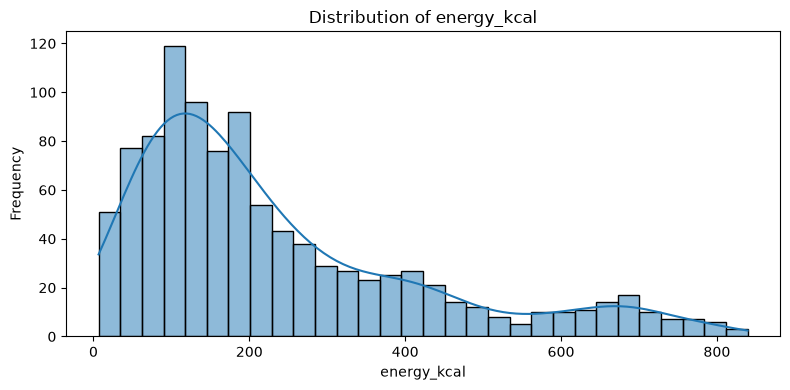

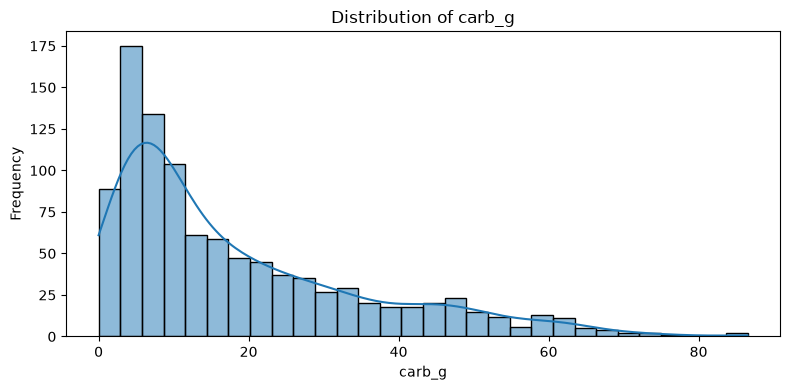

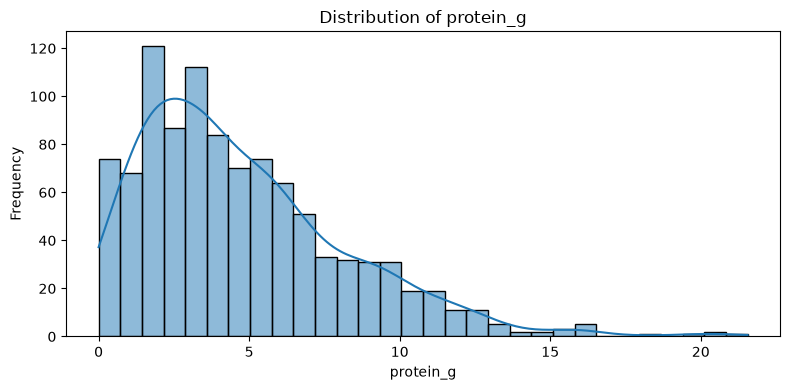

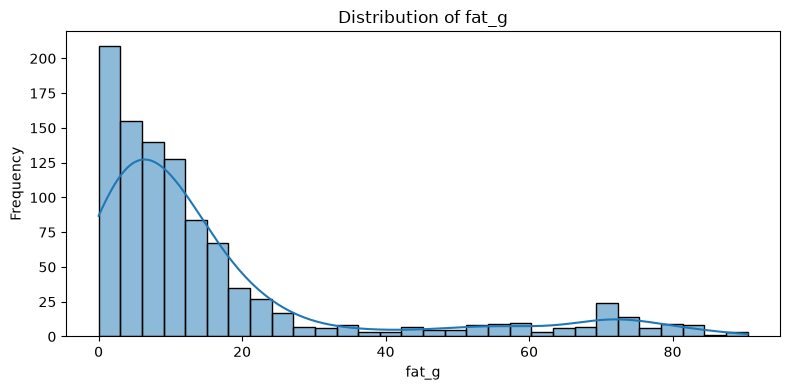

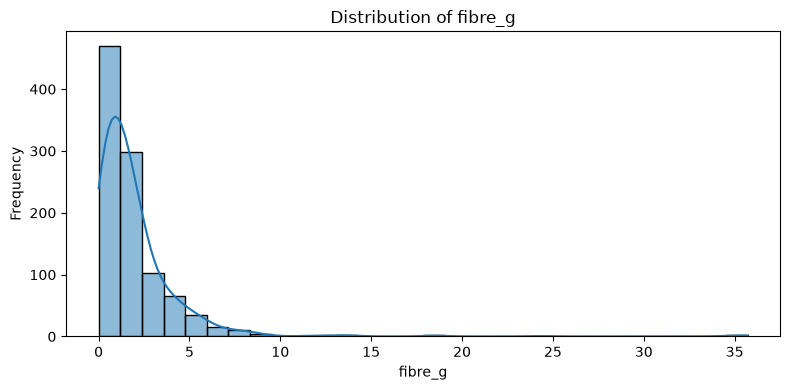

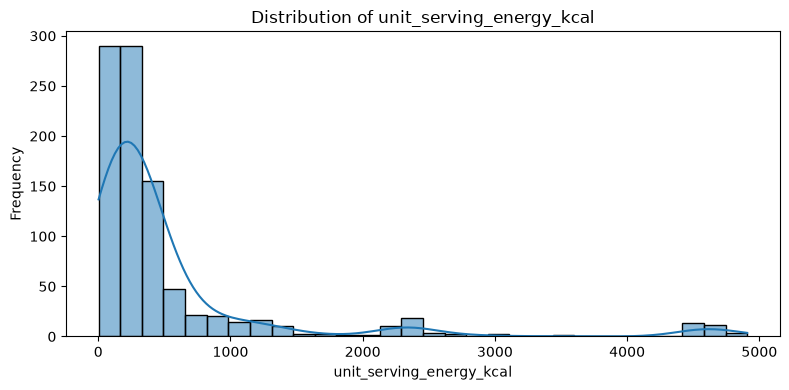

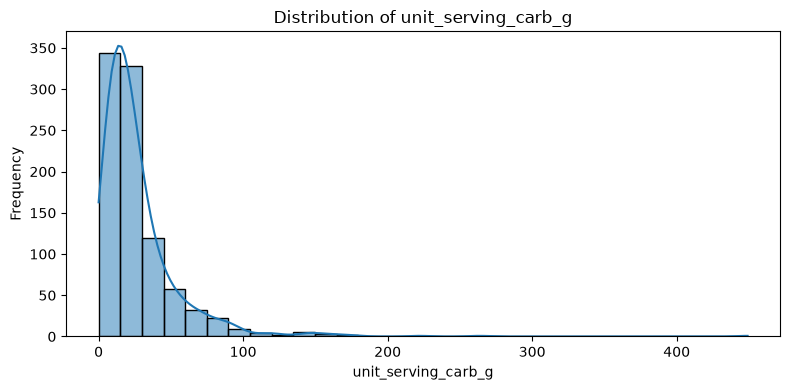

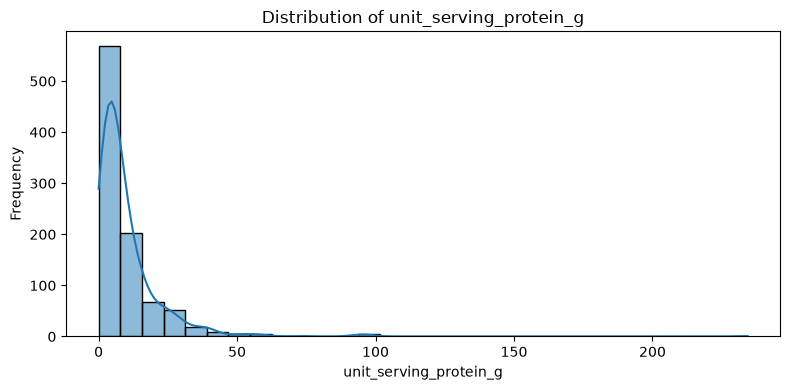

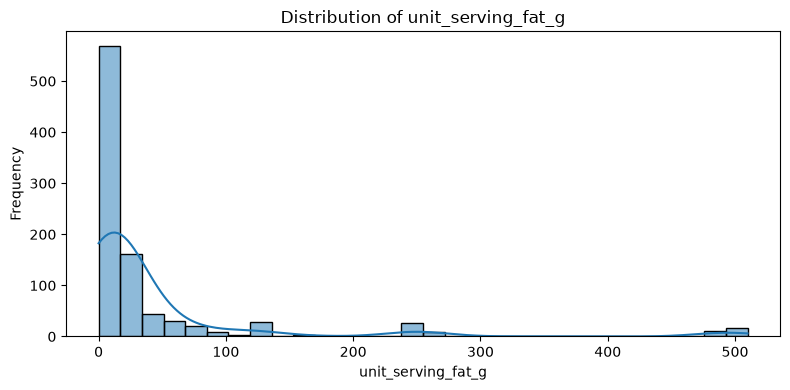

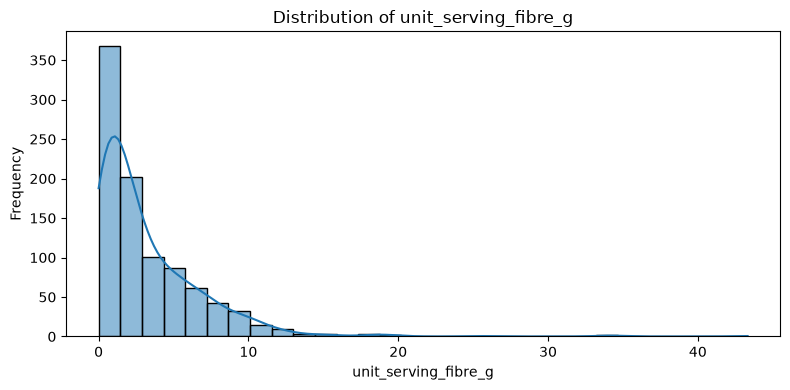

In [60]:
# C52 — Plot required nutrition distributions

import matplotlib.pyplot as plt
import seaborn as sns

c52_columns = [
    "energy_kcal",
    "carb_g",
    "protein_g",
    "fat_g",
    "fibre_g",
    "unit_serving_energy_kcal",
    "unit_serving_carb_g",
    "unit_serving_protein_g",
    "unit_serving_fat_g",
    "unit_serving_fibre_g"
]

for col in c52_columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(c49_df[col].dropna(), bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

### Observation — C52: Nutrition Distribution Plots

- **Energy per 100 g:** The distribution is right-skewed, with most records concentrated at lower calorie values and a smaller number of high-calorie recipes.
- **Carbohydrates and protein:** Both distributions are right-skewed, with most records having relatively low-to-moderate values.
- **Fat:** Most records have lower fat values, while a smaller group has substantially higher values.
- **Fibre:** Most values are concentrated near the lower end, with a few unusually high observations.
- **Per-serving energy and fibre:** Both distributions are strongly right-skewed, with some extreme values requiring investigation.

**Conclusion:** The nutrition fields are not normally distributed, and several values are unusually high. These observations should be investigated before deciding whether any correction is necessary.

**Limitation:** Distribution plots alone cannot establish that a value is incorrect. Extreme values may reflect legitimate recipes or unusually large serving sizes.

### C53 — Flag suspicious or invalid values

In [61]:
# C53 — Flag suspicious or invalid nutrition values

c53_columns = [
    "energy_kcal",
    "carb_g",
    "protein_g",
    "fat_g",
    "fibre_g",
    "unit_serving_energy_kcal",
    "unit_serving_carb_g",
    "unit_serving_protein_g",
    "unit_serving_fat_g",
    "unit_serving_fibre_g"
]

c53_results = []

for col in c53_columns:
    series = c49_df[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    c53_results.append({
        "Column": col,
        "Negative Values": int((series < 0).sum()),
        "IQR Lower Bound": round(lower_bound, 2),
        "IQR Upper Bound": round(upper_bound, 2),
        "Below Lower Bound": int((series < lower_bound).sum()),
        "Above Upper Bound": int((series > upper_bound).sum())
    })

c53_summary = pd.DataFrame(c53_results)

print("C53 — Suspicious Nutrition Value Summary")
print("-" * 90)
print(c53_summary.to_string(index=False))

C53 — Suspicious Nutrition Value Summary
------------------------------------------------------------------------------------------
                  Column  Negative Values  IQR Lower Bound  IQR Upper Bound  Below Lower Bound  Above Upper Bound
             energy_kcal                0          -220.82           637.84                  0                 67
                  carb_g                0           -26.36            58.81                  0                 35
               protein_g                0            -4.66            13.36                  0                 19
                   fat_g                0           -15.56            36.68                  0                129
                 fibre_g                0            -2.05             4.98                  0                 73
unit_serving_energy_kcal                0          -290.53           865.26                  0                122
     unit_serving_carb_g                0           -21.95            

### Observation — C53: Suspicious or Invalid Nutrition Values

- No negative values were found in any of the 10 required nutrition fields.
- The IQR method flagged high values in all 10 fields.
- Per 100 g, fat has the highest number of upper-bound flags (129), followed by energy (67) and fibre (73).
- Per serving, energy has 122 upper-bound flags and fat has 129, indicating that some serving-level values are unusually high.
- No values fell below the calculated lower IQR bounds.

**Conclusion:** No negative nutrition values were detected. Several high values require further investigation, particularly fat and energy per serving.

**Limitation:** IQR flags indicate statistical extremes, not necessarily incorrect data. Values will not be changed or removed based on these flags alone.

### C54 — Verify suspicious records

In [66]:
# C54 — Verify records with the highest per-serving calories

c54_columns = [
    "food_code",
    "food_name",
    "servings_unit",
    "energy_kcal",
    "unit_serving_energy_kcal",
    "fat_g",
    "unit_serving_fat_g"
]

c54_top_records = (
    c49_df.nlargest(10, "unit_serving_energy_kcal")[c54_columns]
    .reset_index(drop=True)
)

print("C54 — Top 10 Records by Per-Serving Calories")
print("-" * 100)
print(c54_top_records.round(2).to_string(index=False))

C54 — Top 10 Records by Per-Serving Calories
----------------------------------------------------------------------------------------------------
food_code                                  food_name servings_unit  energy_kcal  unit_serving_energy_kcal  fat_g  unit_serving_fat_g
   ASC137 Spaghetti and cheese balls in tomato sauce         plate       508.32                   4908.38  52.08              502.89
   ASC118                               Paneer pulao         plate       581.91                   4875.84  59.81              501.14
   ASC216                               Methi chaman          bowl       475.62                   4763.38  50.91              509.84
   ASC249                                Tomato fish          bowl       489.79                   4740.81  51.91              502.43
   ASC225                       Paneer makhana korma          bowl       775.82                   4709.20  82.76              502.34
   ASC200                         Paneer kofta curry    

### Observation — C54: Verification of Suspicious Records

- The 10 records with the highest per-serving calories range from approximately 4,645 to 4,908 kcal.
- Their per-serving fat values range from approximately 486 to 510 g.
- The corresponding per-100 g energy values range from approximately 455 to 776 kcal.
- The records use generic serving descriptions such as `plate` and `bowl`, but their actual serving weights are not provided in this output.
- These values may reflect unusually large source-defined servings or require further verification.

**Conclusion:** The records are suspicious because of their exceptionally high per-serving energy and fat values. However, the available information is insufficient to confirm data errors.

**Limitation:** Actual serving weights and independent source verification are unavailable in this check. No values have been changed or removed.


_____
____

# Task 12 — Standardize food names

### C56 — Normalize food names and formatting

This cell will standardize capitalization and remove unnecessary leading, trailing and repeated whitespace. It will preserve the original food names in a separate column so we can trace every change.

In [67]:
# C56 — Normalize Food Names and Formatting

c56_df = c49_df.copy()

c56_df["food_name_original"] = c56_df["food_name"]

c56_df["food_name_normalized"] = (
    c56_df["food_name"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.lower()
)

print("Records:", len(c56_df))
print("Unique original food names:", c56_df["food_name_original"].nunique())
print("Unique normalized food names:", c56_df["food_name_normalized"].nunique())

print("\nSample normalized names:")
print(
    c56_df[
        ["food_code", "food_name_original", "food_name_normalized"]
    ].head(10).to_string(index=False)
)

Records: 1014
Unique original food names: 1014
Unique normalized food names: 1014

Sample normalized names:
food_code                        food_name_original                      food_name_normalized
   ASC001                      Hot tea (Garam Chai)                      hot tea (garam chai)
   ASC002                            Instant coffee                            instant coffee
   ASC003                            Espreso coffee                            espreso coffee
   ASC004                                  Iced tea                                  iced tea
   ASC005               Raw mango drink (Aam panna)               raw mango drink (aam panna)
   ASC006           Fruit Punch (with fresh juices)           fruit punch (with fresh juices)
   ASC007               Fruit Punch (with squashes)               fruit punch (with squashes)
   ASC008                                  Lemonade                                  lemonade
   ASC009                                 Lem-

### Observation — C56: Normalize Food Names and Formatting

- The filtered nutrition dataset contains 906 records and 906 unique original food names.
- Food names were converted to lowercase, and leading, trailing and repeated whitespace was removed.
- The original food names were preserved in `food_name_original`, while normalized names were stored in `food_name_normalized`.
- All 906 names changed during normalization, primarily due to lowercase conversion.
- The number of unique names remained 906 after normalization.

**Conclusion:** Food names have been standardized for consistent text matching, while original source names remain available for traceability.

**Limitation:** This step standardizes formatting only. It does not correct spelling mistakes, merge synonyms or establish that two differently named recipes are equivalent.

### Duplicate audit
duplicate food codes, exact original food names and normalized food names without deleting anything.

In [68]:

# INDB EDA — Duplicate Audit
# No records are deleted or modified in this cell.

import pandas as pd

# 1. Duplicate food codes in the original dataset
c45_duplicate_codes = c45_df[
    c45_df["food_code"].duplicated(keep=False)
].sort_values("food_code")

# 2. Exact repeated original food names
c45_duplicate_names = c45_df[
    c45_df["food_name"].duplicated(keep=False)
].sort_values("food_name")

# 3. Repeated normalized names in the current lookup candidates
c56_duplicate_normalized = c56_df[
    c56_df["food_name_normalized"].duplicated(keep=False)
].sort_values("food_name_normalized")

print("INDB — Duplicate Audit")
print("=" * 65)

print("\n1. Original dataset")
print("Total records:", len(c45_df))
print("Records with duplicated food codes:", len(c45_duplicate_codes))
print("Distinct duplicated food codes:",
      c45_duplicate_codes["food_code"].nunique())

print("\n2. Exact repeated original food names")
print("Records with repeated names:", len(c45_duplicate_names))
print("Distinct repeated names:",
      c45_duplicate_names["food_name"].nunique())

if not c45_duplicate_names.empty:
    print("\nRepeated-name examples:")
    print(
        c45_duplicate_names[
            ["food_code", "food_name", "energy_kcal",
             "servings_unit", "unit_serving_energy_kcal"]
        ].head(30).to_string(index=False)
    )

print("\n3. Normalized names in lookup candidates")
print("Lookup candidate records:", len(c56_df))
print("Records with repeated normalized names:",
      len(c56_duplicate_normalized))
print("Distinct repeated normalized names:",
      c56_duplicate_normalized["food_name_normalized"].nunique())

if not c56_duplicate_normalized.empty:
    print("\nRepeated normalized-name examples:")
    print(
        c56_duplicate_normalized[
            ["food_code", "food_name_original",
             "food_name_normalized", "energy_kcal",
             "servings_unit", "unit_serving_energy_kcal"]
        ].head(30).to_string(index=False)
    )


INDB — Duplicate Audit

1. Original dataset
Total records: 1014
Records with duplicated food codes: 0
Distinct duplicated food codes: 0

2. Exact repeated original food names
Records with repeated names: 0
Distinct repeated names: 0

3. Normalized names in lookup candidates
Lookup candidate records: 1014
Records with repeated normalized names: 0
Distinct repeated normalized names: 0
